# Trabajo Práctico Final - Aprendizaje de Máquina


## Integrantes

a2708 - Angie Mariana Marroquin Diaz

a2709 - Duvan Steven Orozco Suarez

## Información sobre el dataset

**Fuente:** [Stellar Classification Dataset - SDSS17 (Kaggle, fedesoriano)](https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17)

El Stellar Classification Dataset (SDSS17) proviene del **Sloan Digital Sky Survey (SDSS), Data Release 17**, uno de los relevamientos astronómicos más grandes del mundo. El dataset contiene **100.000 observaciones** espectroscópicas del cielo, cada una clasificada como **estrella (STAR)**, **galaxia (GALAXY)** o **quásar (QSO)**.

- **Archivo:** `star_classification.csv`
- **Dimensiones (archivo original):** 100.000 filas × 18 columnas. Tras la limpieza quedan 99.999 registros (ver *Calidad de datos*).
### Diccionario de variables

| Variable | Grupo | Descripción |
|---|---|---|
| `obj_ID` | Identificador | ID único del objeto en el catálogo de imágenes |
| `alpha` | Posición | Ascensión recta (ángulo, época J2000) |
| `delta` | Posición | Declinación (ángulo, época J2000) |
| `u` | Fotometría | Magnitud en el filtro ultravioleta |
| `g` | Fotometría | Magnitud en el filtro verde |
| `r` | Fotometría | Magnitud en el filtro rojo |
| `i` | Fotometría | Magnitud en el filtro infrarrojo cercano |
| `z` | Fotometría | Magnitud en el filtro infrarrojo |
| `run_ID` | Metadata técnica | Número de corrida del escaneo |
| `rerun_ID` | Metadata técnica | Número de reprocesamiento de la imagen |
| `cam_col` | Metadata técnica | Columna de cámara (1 a 6) dentro de la corrida |
| `field_ID` | Metadata técnica | Número de campo |
| `spec_obj_ID` | Identificador | ID del objeto espectroscópico |
| **`class`** | **Variable objetivo** | **Tipo de objeto: GALAXY, STAR o QSO** |
| `redshift` | Espectroscopía | Corrimiento al rojo (aumento de la longitud de onda de la luz) |
| `plate` | Metadata técnica | ID de la placa del espectrógrafo |
| `MJD` | Metadata técnica | Fecha juliana modificada de la observación |
| `fiber_ID` | Metadata técnica | Fibra óptica que dirigió la luz al plano focal |

### Notas para la interpretación

- **Magnitudes (`u`, `g`, `r`, `i`, `z`):** la escala es inversa, así que **un valor menor indica un objeto más brillante**.
- **Redshift:** mide qué tanto se "estira" la luz de un objeto que se aleja. A mayor redshift, mayor distancia. Las estrellas pertenecen a nuestra galaxia, por eso su redshift es cercano a 0. Los quásares están entre los objetos más lejanos.
- **Metadata técnica e identificadores:** describen *cómo* y *cuándo* se hizo la observación, no las propiedades físicas del objeto. En principio no deberían aportar valor predictivo y pueden introducir fuga de información.

## Objetivo del análisis

### Planteamiento del problema

Se trata de un problema de **clasificación supervisada multiclase**: predecir si un objeto astronómico es una **estrella**, una **galaxia** o un **quásar** a partir de sus características fotométricas (magnitudes en cinco bandas) y espectroscópicas (redshift).

Clasificar estos objetos de forma automática es clave en astronomía. Los relevamientos modernos generan millones de observaciones y la clasificación manual no escala.

### Objetivo general

Construir, evaluar y comparar distintos modelos de *machine learning* para clasificar objetos celestes, e identificar el de mejor desempeño y las variables que más contribuyen a la clasificación.

### Objetivos específicos

1. **Explorar** el dataset: calidad de los datos, distribución de la variable objetivo y comportamiento de las variables por clase.
2. **Identificar** las variables con mayor poder discriminante y aquellas sin valor predictivo (identificadores, metadata técnica).
3. **Preparar** los datos: limpieza, tratamiento de valores atípicos, *feature engineering* (por ejemplo, índices de color) y escalado.
4. **Entrenar y comparar** varios modelos de clasificación.
5. **Evaluar** los resultados con métricas adecuadas para clases desbalanceadas e interpretar los errores del mejor modelo.

### Preguntas guía

- ¿Qué tan desbalanceadas están las clases y cómo afecta eso al modelado?
- ¿Es el redshift suficiente por sí solo para separar las clases?
- ¿Qué tanto aportan los índices de color frente a las magnitudes individuales?
- ¿Qué modelo ofrece el mejor equilibrio entre desempeño, interpretabilidad y costo computacional?

### Métricas de evaluación

| Métrica | Uso |
|---|---|
| **F1-score macro** | Métrica principal: pondera por igual las tres clases, sin importar su tamaño |
| Accuracy | Referencia general (puede engañar si hay desbalance) |
| Precision y recall por clase | Detectar qué clases se confunden más |
| Matriz de confusión | Analizar los patrones de error |

### Modelos a comparar

- Regresión Logística (*baseline*)
- K-Nearest Neighbors (KNN)
- Árbol de Decisión
- Random Forest
- Gradient Boosting (XGBoost / LightGBM)
- Support Vector Machine (SVM)

## Instalación de librerías

In [ ]:
!pip install -q kagglehub xgboost lightgbm

In [ ]:
# Librerías requeridas
import os
import time
import warnings
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import randint, uniform, loguniform

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import (StratifiedKFold, train_test_split, cross_val_score,
                                     cross_validate, RandomizedSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Configuración general
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

# Constantes del proyecto
RANDOM_STATE = 42
CLASS_ORDER = ["GALAXY", "STAR", "QSO"]
BANDS = ["u", "g", "r", "i", "z"]

## Carga del dataset

In [ ]:
path = kagglehub.dataset_download("fedesoriano/stellar-classification-dataset-sdss17")
print("Ruta de descarga:", path)
print("Archivos:", os.listdir(path))

df = pd.read_csv(
    os.path.join(path, "star_classification.csv"),
    dtype={"obj_ID": str, "spec_obj_ID": str},
)

# obj_ID viene truncado en el archivo original (ver nota abajo) → se descarta
df = df.drop(columns=["obj_ID"])

print(f"\nDataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print("spec_obj_ID únicos:", df["spec_obj_ID"].nunique())

100%|██████████| 6.89M/6.89M [00:00<00:00, 62.5MB/s]

Extracting files...


Ruta de descarga: /root/.cache/kagglehub/datasets/fedesoriano/stellar-classification-dataset-sdss17/versions/1
Archivos: ['star_classification.csv']

Dataset cargado: 100,000 filas × 17 columnas
spec_obj_ID únicos: 100000


> **Nota sobre `obj_ID`:** en el archivo original esta columna fue guardada después de pasar por `float64`, por lo que sus 19 dígitos quedaron truncados (los IDs terminan en patrones como `...232` o `...360`). Por eso, objetos distintos del mismo campo del cielo comparten el mismo ID, y no es confiable como identificador. Se usa **`spec_obj_ID`**, que se conserva íntegro y es único por fila, como llave de cada observación. `obj_ID` se descarta desde la carga.

## Exploración y análisis de datos

In [ ]:
display(df.head())
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.info()

,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,135.6891,32.4946,23.8788,22.2753,20.3950,19.1657,18.7937,3606,301,2,79,6543777369295181824,GALAXY,0.6348,5812,56354,171
1,144.8261,31.2742,24.7776,22.8319,22.5844,21.1681,21.6143,4518,301,5,119,11760142036707334144,GALAXY,0.7791,10445,58158,427
2,142.1888,35.5824,25.2631,22.6639,20.6098,19.3486,18.9483,3606,301,2,120,5152200256025548800,GALAXY,0.6442,4576,55592,299
3,338.7410,-0.4028,22.1368,23.7766,21.6116,20.5045,19.2501,4192,301,3,214,10301071412954421248,GALAXY,0.9323,9149,58039,775
4,345.2826,21.1839,19.4372,17.5803,16.4975,15.9771,15.5446,8102,301,3,137,6891864880783316992,GALAXY,0.1161,6121,56187,842


Filas: 100,000 | Columnas: 17
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 17 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   alpha        100000 non-null  float64
 1   delta        100000 non-null  float64
 2   u            100000 non-null  float64
 3   g            100000 non-null  float64
 4   r            100000 non-null  float64
 5   i            100000 non-null  float64
 6   z            100000 non-null  float64
 7   run_ID       100000 non-null  int64  
 8   rerun_ID     100000 non-null  int64  
 9   cam_col      100000 non-null  int64  
 10  field_ID     100000 non-null  int64  
 11  spec_obj_ID  100000 non-null  object 
 12  class        100000 non-null  object 
 13  redshift     100000 non-null  float64
 14  plate        100000 non-null  int64  
 15  MJD          100000 non-null  int64  
 16  fiber_ID     100000 non-null  int64  
dtypes: float64(8), int64(7), object(2)
mem

- El dataset tiene **100.000 registros**. Tras descartar `obj_ID` quedan **17 columnas**.
- **No hay valores nulos** en ninguna columna.
- **Tipos de datos:**
  - Numéricas continuas: posición (`alpha`, `delta`), magnitudes (`u`, `g`, `r`, `i`, `z`) y `redshift`.
  - Enteros de metadata técnica: `run_ID`, `rerun_ID`, `cam_col`, `field_ID`, `plate`, `MJD`, `fiber_ID`.
  - Texto: `spec_obj_ID` (llave única) y `class` (variable objetivo).
- `cam_col` es numérica, pero conceptualmente es **categórica** (columna de cámara del 1 al 6).
- Que no haya nulos no garantiza datos limpios: SDSS usa valores centinela (como **-9999**) para mediciones faltantes. Eso se revisa a continuación.

### Calidad de datos

Se revisan duplicados, columnas constantes (sin variabilidad) y valores imposibles o centinela en las magnitudes.

In [ ]:
calidad = pd.DataFrame({
    "dtype": df.dtypes,
    "valores_unicos": df.nunique(),
    "min": df.min(numeric_only=True),
    "max": df.max(numeric_only=True),
})

display(calidad)

,dtype,valores_unicos,min,max
MJD,int64,2180,51608.0000,58932.0000
alpha,float64,99999,0.0055,359.9998
cam_col,int64,6,1.0000,6.0000
class,object,3,NaN,NaN
delta,float64,99999,-18.7853,83.0005
fiber_ID,int64,1000,1.0000,1000.0000
field_ID,int64,856,11.0000,989.0000
g,float64,92651,-9999.0000,31.6022
i,float64,92019,9.4699,32.1415
plate,int64,6284,266.0000,12547.0000


In [ ]:
print("Filas duplicadas:", df.duplicated().sum())
print("spec_obj_ID duplicados:", df["spec_obj_ID"].duplicated().sum())

constantes = [c for c in df.columns if df[c].nunique() == 1]
print("Columnas constantes:", constantes)

Filas duplicadas: 0
spec_obj_ID duplicados: 0
Columnas constantes: ['rerun_ID']


| Revisión | Resultado | Decisión |
|---|---|---|
| Valores nulos | 0 | Sin acción |
| Filas duplicadas | 0 | Sin acción |
| `spec_obj_ID` duplicados | 0 — cada fila es una observación única | Se usa como llave |
| `obj_ID` | Truncado en el archivo original | Descartado desde la carga |
| Columnas constantes | `rerun_ID` (siempre 301) | **Eliminar**: no aporta información |
| Valores centinela | 1 fila (clase STAR) con -9999 en `u`, `g` y `z` | **Eliminar**: es 0,001% de los datos e imputar 3 de 5 magnitudes no tiene sentido |
| Redshift negativo | 13.682 STAR y 42 GALAXY | **Mantener**: es físicamente válido (ver nota) |

**Sobre el redshift negativo:** un valor negativo (*blueshift*) indica que el objeto se acerca a nosotros. Es esperable en estrellas de la Vía Láctea, que se mueven en todas direcciones y tienen redshift ≈ 0. Las 42 galaxias con redshift negativo probablemente son galaxias muy cercanas o ruido de medición, ya que el mínimo es apenas -0,01.

**Otros rangos observados:**
- `alpha` cubre 0°–360° y `delta` va de -18,8° a 83°, lo que refleja la cobertura del cielo del survey (principalmente hemisferio norte).
- `MJD` va de 51.608 a 58.932, es decir, observaciones entre el año 2000 y 2020.
- `redshift` llega hasta 7,01, un valor típico de quásares muy lejanos.

In [ ]:
# Limpieza final: eliminar valores centinela y columna constante
mask_bad = (df[BANDS] == -9999).any(axis=1)
print(f"Filas con valores centinela (-9999): {mask_bad.sum()}")

df_clean = df.loc[~mask_bad].drop(columns=["rerun_ID"]).reset_index(drop=True)
print(f"Antes: {df.shape} → Después: {df_clean.shape}")


Filas con valores centinela (-9999): 1
Antes: (100000, 17) → Después: (99999, 16)


### Distribución de la variable objetivo

Se analiza la proporción de cada clase para identificar posibles desbalances que afecten el entrenamiento y la evaluación de los modelos.

,n,%
class,,
GALAXY,59445,59.4500
STAR,21593,21.5900
QSO,18961,18.9600


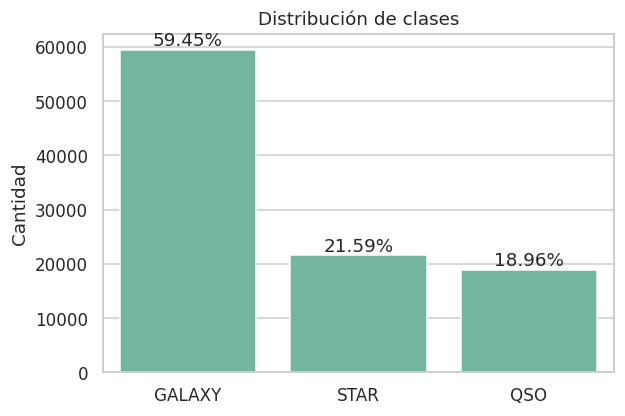

Ratio mayoritaria/minoritaria: 3.14


In [ ]:
counts = df_clean["class"].value_counts().reindex(CLASS_ORDER)
pct = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({"n": counts, "%": pct}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_clean, x="class", order=CLASS_ORDER, ax=ax)
for p, v in zip(ax.patches, pct):
    ax.annotate(f"{v}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Distribución de clases")
ax.set_xlabel("")
ax.set_ylabel("Cantidad")
plt.show()

print(f"Ratio mayoritaria/minoritaria: {counts.max() / counts.min():.2f}")

- Existe un **desbalance moderado**: la clase mayoritaria (GALAXY) es **3,14 veces** más frecuente que la minoritaria (QSO). STAR y QSO tienen proporciones similares entre sí.
- **Baseline de referencia:** un clasificador que siempre prediga GALAXY obtendría **59,45% de accuracy** y un F1 macro de ~0,25. Cualquier modelo útil debe superar ampliamente estos valores.
- Esto confirma la elección del **F1 macro** como métrica principal, ya que pondera por igual el desempeño en las tres clases.

**Decisiones para el modelado:**
1. **División train/test estratificada** (`stratify=y`) para preservar las proporciones en ambos conjuntos.
2. **Validación cruzada estratificada** (`StratifiedKFold`).
3. Probar **`class_weight="balanced"`** en los modelos que lo permitan.
4. Técnicas de sobremuestreo como SMOTE no parecen necesarias con este nivel de desbalance y ~19.000 ejemplos en la clase minoritaria. Se evaluarán solo si el recall de QSO resulta bajo.

### Estadística descriptiva

Se analizan las variables numéricas de interés físico: posición, magnitudes, redshift y fecha de observación. Las variables de metadata técnica se revisan más adelante.

In [ ]:
NUM_COLS = ["alpha", "delta"] + BANDS + ["redshift", "MJD"]

desc = df_clean[NUM_COLS].describe().T
desc["asimetria"] = df_clean[NUM_COLS].skew()
desc["curtosis"] = df_clean[NUM_COLS].kurt()
display(desc)

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
alpha,99999.0000,177.6287,96.5026,0.0055,127.5177,180.9005,233.8950,359.9998,-0.0285,-0.5372
delta,99999.0000,24.1356,19.6446,-18.7853,5.1475,23.6465,39.9016,83.0005,0.1751,-1.0431
u,99999.0000,22.0807,2.2511,10.9962,20.3524,22.1791,23.6875,32.7814,-0.0703,-0.5390
g,99999.0000,20.6316,2.0374,10.4982,18.9652,21.0999,22.1238,31.6022,-0.4280,-0.3707
r,99999.0000,19.6458,1.8548,9.8221,18.1358,20.1253,21.0448,29.5719,-0.5079,-0.3761
i,99999.0000,19.0849,1.7579,9.4699,17.7323,19.4051,20.3965,32.1415,-0.4042,-0.2348
z,99999.0000,18.7690,1.7660,9.6123,17.4608,19.0046,19.9211,29.3837,-0.2568,-0.2100
redshift,99999.0000,0.5767,0.7307,-0.0100,0.0545,0.4242,0.7042,7.0112,2.5236,9.9729
MJD,99999.0000,55588.6537,1808.4922,51608.0000,54234.0000,55869.0000,56777.0000,58932.0000,-0.3819,-0.7732



**Variables generales**

- **Redshift:** distribución fuertemente **asimétrica a la derecha** (asimetría = 2,52; curtosis = 9,97). La media (0,58) supera a la mediana (0,42), y el 75% de los objetos tiene redshift menor a 0,70, pero la cola llega hasta 7,01 por los quásares más lejanos. Se considerará una **transformación logarítmica** para los modelos sensibles a la escala.
- **Magnitudes (`u`, `g`, `r`, `i`, `z`):** distribuciones aproximadamente simétricas (asimetría entre -0,51 y -0,07), con valores entre ~9,5 y ~32,8. La banda `u` es la más dispersa (desv. est. = 2,25), algo esperable porque el ultravioleta es la banda de menor sensibilidad. Las medianas disminuyen de `u` (22,18) a `z` (19,00): en general los objetos se ven más brillantes hacia el infrarrojo.
- **Posición:** `alpha` cubre todo el rango (0°–360°) y `delta` va de -18,8° a 83°. Ambas tienen curtosis negativa, lo que indica una cobertura extendida del cielo y no concentrada. Reflejan el diseño del survey, no propiedades físicas.
- **`MJD`:** observaciones entre los años 2000 y 2020 (MJD 51.608 – 58.932).

In [ ]:
display(
    df_clean.groupby("class")[BANDS + ["redshift"]]
    .median()
    .reindex(CLASS_ORDER)
)

,u,g,r,i,z,redshift
class,,,,,,
GALAXY,22.8418,21.5822,20.1046,19.2237,18.7666,0.4563
STAR,21.0106,19.5428,18.9551,18.5924,18.3192,-0.0001
QSO,21.5032,21.0563,20.7727,20.5821,20.3740,1.6172


**Comparación por clase (medianas)**

1. **El redshift separa nítidamente las tres clases.** Las estrellas tienen mediana ≈ 0, coherente con que pertenecen a la Vía Láctea. Las galaxias se ubican en 0,46 y los quásares en 1,62 (unas 3,5 veces más). Es la **variable con mayor poder discriminante**.

2. **Las estrellas son las más brillantes en todas las bandas** (menor magnitud), porque están mucho más cerca que galaxias y quásares.

3. **Las magnitudes individuales se cruzan entre clases.** En `u` las galaxias son las más débiles (22,84), pero en `z` los quásares son los más débiles (20,37). Ninguna banda aislada separa bien las clases. Lo que las distingue es **la forma del espectro**: cuánto cambia el brillo de una banda a otra.

4. **La pendiente espectral diferencia a cada clase** (diferencia de medianas entre `u` y `z`):
   - **GALAXY: ~4,1 mag** → espectro muy "rojo": débiles en el ultravioleta y mucho más brillantes en el infrarrojo, típico de poblaciones de estrellas viejas.
   - **STAR: ~2,7 mag** → pendiente intermedia.
   - **QSO: ~1,1 mag** → espectro casi "plano": brillo similar en todas las bandas, característico de la emisión de un núcleo activo.

**Implicación para el modelado:** además del redshift, los **índices de color** (`u−g`, `g−r`, `r−i`, `i−z`) deberían aportar más información que las magnitudes por separado. Se construirán en la etapa de *feature engineering* y se exploran más adelante, en la sección *Índices de color*.

### Distribuciones univariadas por clase

Se compara la distribución de cada variable física entre las tres clases para identificar cuáles tienen mayor poder de separación.

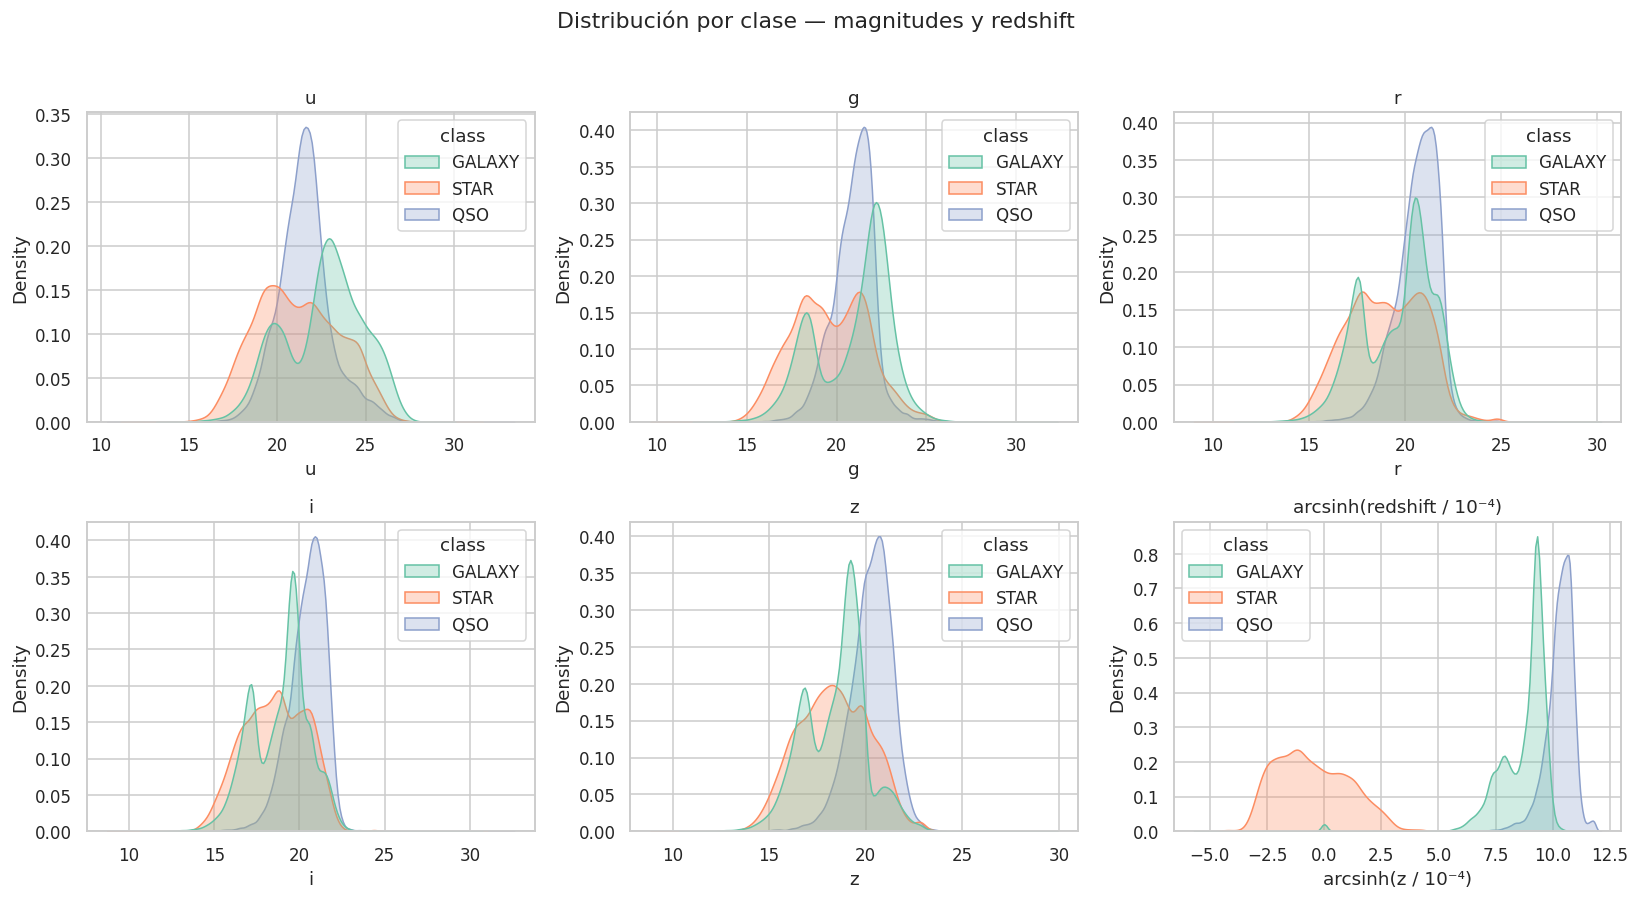

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat[:5], BANDS):
    sns.kdeplot(data=df_clean, x=col, hue="class", hue_order=CLASS_ORDER,
                common_norm=False, fill=True, alpha=0.3, ax=ax)
    ax.set_title(col)

S = 1e-4
tmp = df_clean.assign(asinh_redshift=np.arcsinh(df_clean["redshift"] / S))

sns.kdeplot(data=tmp, x="asinh_redshift", hue="class", hue_order=CLASS_ORDER,
            common_norm=False, fill=True, alpha=0.3, ax=axes.flat[5])
axes.flat[5].set_title("arcsinh(redshift / 10⁻⁴)")
axes.flat[5].set_xlabel("arcsinh(z / 10⁻⁴)")

plt.suptitle("Distribución por clase — magnitudes y redshift", y=1.02)
plt.tight_layout()
plt.show()

**Magnitudes**

- **Las distribuciones de las tres clases se solapan fuertemente en las cinco bandas.** Ninguna magnitud por sí sola permite separar las clases, lo que confirma lo observado en las medianas.
- **Los quásares (QSO) tienen distribuciones angostas y concentradas** alrededor de 21 mag en todas las bandas. Esto es coherente con su espectro "plano" y con el límite de detección del survey: se observan principalmente en el extremo débil.
- **Las galaxias muestran distribuciones bimodales** en `g`, `r`, `i` y `z`, con un pico brillante (~17–18 mag) y otro débil (~19–22 mag).
- **Las estrellas presentan distribuciones amplias** y son las únicas con presencia importante en el extremo brillante (<17 mag).

**Redshift (transformación `arcsinh(z / 10⁻⁴)`)**

Para visualizar el redshift se usa `arcsinh(z / 10⁻⁴)`. Esta transformación es casi lineal cerca de 0, se comporta como un logaritmo para valores grandes y está definida para valores negativos, así que conserva el signo (los *blueshifts* de las estrellas) sin sumar constantes artificiales. Como referencia: z = 0,0002 → ≈ 1,4; z = 0,13 → ≈ 7,9; z = 0,5 → ≈ 9,2; z = 2 → ≈ 10,6.

Con esta escala aparecen tres poblaciones claramente diferenciadas:

- **STAR:** concentradas alrededor de 0, aproximadamente entre -4,4 y +4,4 (|z| < 0,004), con valores a ambos lados por los movimientos de las estrellas de la Vía Láctea. **No se solapan con las otras clases**, salvo un pequeño grupo de galaxias con redshift ≈ 0.
- **GALAXY:** distribución **bimodal**, con un pico principal en ~9,2 (z ~0,5) y uno secundario en ~7,9 (z ~0,13), y una cola hacia valores menores.
- **QSO:** pico en ~10,6 (z ~2), aproximadamente entre ~8 y ~11,9 (z de ~0,3 a ~7).


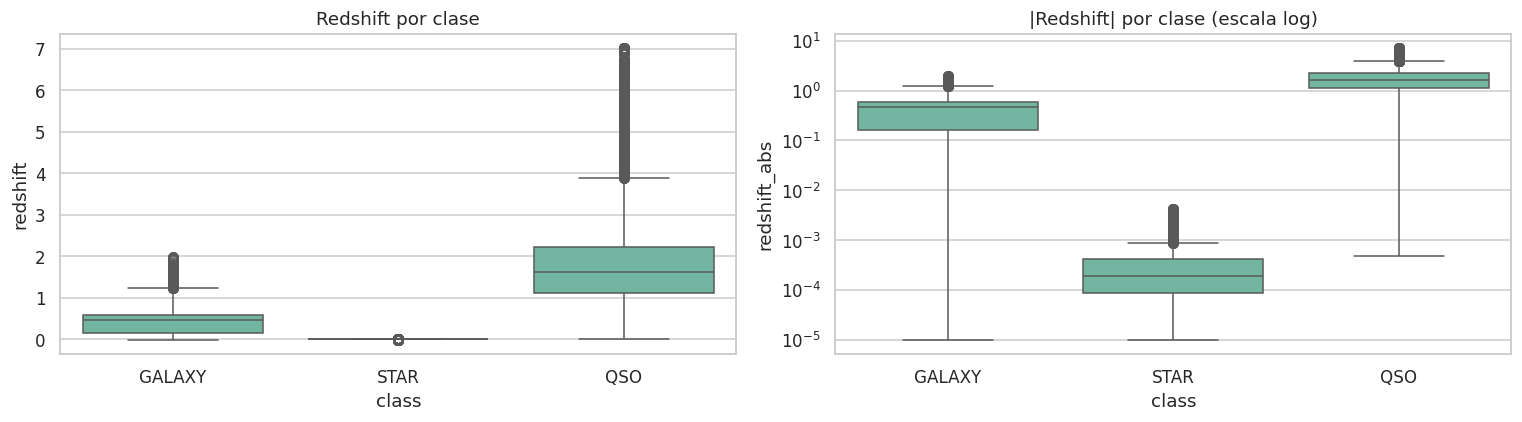

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(data=df_clean, x="class", y="redshift", order=CLASS_ORDER, ax=axes[0])
axes[0].set_title("Redshift por clase")

tmp = df_clean.assign(redshift_abs=df_clean["redshift"].abs() + 1e-5)
sns.boxplot(data=tmp, x="class", y="redshift_abs", order=CLASS_ORDER, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("|Redshift| por clase (escala log)")

plt.tight_layout()
plt.show()

**Hallazgos principales:**

1. **STAR vs. resto: separación prácticamente perfecta.** Un solo umbral en el redshift (~10⁻²) bastaría para aislar casi todas las estrellas.
2. **GALAXY vs. QSO: solapamiento parcial** entre redshift ~0,5 y ~1,3, donde se cruzan la cola superior de las galaxias y la cola inferior de los quásares (en la escala lineal, algunas galaxias llegan hasta ~2). **Esta es la zona donde se concentrará la dificultad del modelo** y donde se necesitarán otras variables, como los índices de color.
3. **La bimodalidad de las galaxias aparece tanto en el redshift como en las magnitudes.** Esto sugiere **dos subpoblaciones**: galaxias cercanas y brillantes (redshift ~0,1, magnitudes ~17–18) y galaxias lejanas y débiles (redshift ~0,5, magnitudes ~19–22), seleccionadas probablemente por distintos programas de observación del SDSS.

> **Nota técnica:** en el boxplot en escala logarítmica se suma 10⁻⁵ al valor absoluto del redshift para poder graficar valores ≈ 0 y negativos. Por eso aparece un piso artificial en 10⁻⁵, que corresponde a las galaxias con redshift prácticamente nulo (incluidas las 42 con valor negativo), probablemente galaxias muy cercanas o errores de medición.

**Conclusión:** el redshift es la variable más informativa y, en escala logarítmica, separa casi por completo a las estrellas. La frontera **GALAXY–QSO** es el principal desafío de clasificación, y ahí los índices de color serán clave. Además, se usará una transformación logarítmica con signo del redshift como variable de entrada de los modelos (ver *Preprocesamiento*).


### Índices de color

En astronomía, el **color** de un objeto se mide como la diferencia de magnitudes entre dos bandas (por ejemplo, `u − g`). Al ser una diferencia, elimina el efecto de la distancia sobre el brillo y captura la **forma del espectro**, que es justamente lo que distingue a las clases.

,u_g,g_r,r_i,i_z
class,,,,
GALAXY,1.6404,1.4045,0.7202,0.3908
STAR,1.3194,0.5270,0.2109,0.1155
QSO,0.3934,0.2136,0.1522,0.1573


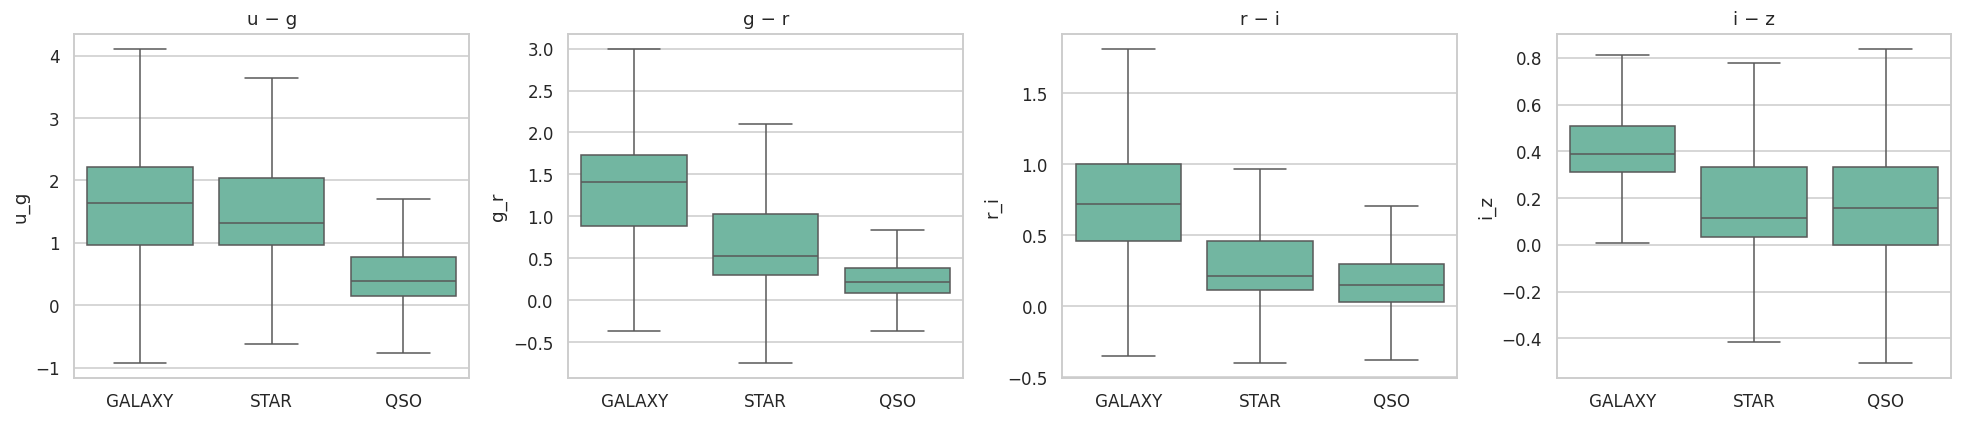

In [ ]:
COLOR_PAIRS = [("u", "g"), ("g", "r"), ("r", "i"), ("i", "z")]
COLORS = [f"{a}_{b}" for a, b in COLOR_PAIRS]

for a, b in COLOR_PAIRS:
    df_clean[f"{a}_{b}"] = df_clean[a] - df_clean[b]

display(df_clean.groupby("class")[COLORS].median().reindex(CLASS_ORDER))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, COLORS):
    sns.boxplot(data=df_clean, x="class", y=col, order=CLASS_ORDER,
                showfliers=False, ax=ax)
    ax.set_title(col.replace("_", " − "))
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Cada índice de color aporta información distinta:**

- **`u − g` separa a los quásares:** su mediana (0,39) es mucho menor que la de galaxias (1,64) y estrellas (1,32), y sus cajas prácticamente no se solapan. Es el **"exceso ultravioleta"** característico de los quásares, históricamente usado para identificarlos.
- **`g − r` y `r − i` separan a las galaxias:** son claramente más "rojas" (1,40 y 0,72) que estrellas y quásares, que se mantienen por debajo de 0,53 y 0,21 respectivamente.
- **`i − z` aporta poco:** galaxias levemente más altas, pero estrellas y quásares se solapan casi por completo. Es el índice menos discriminante.
- **STAR y QSO solo se distinguen bien en `u − g`.** En `r − i` e `i − z` son prácticamente indistinguibles por color, pero el redshift ya los separa perfectamente.

Objetos en la zona de solapamiento:
class
GALAXY    25255
QSO       11672
Name: count, dtype: int64


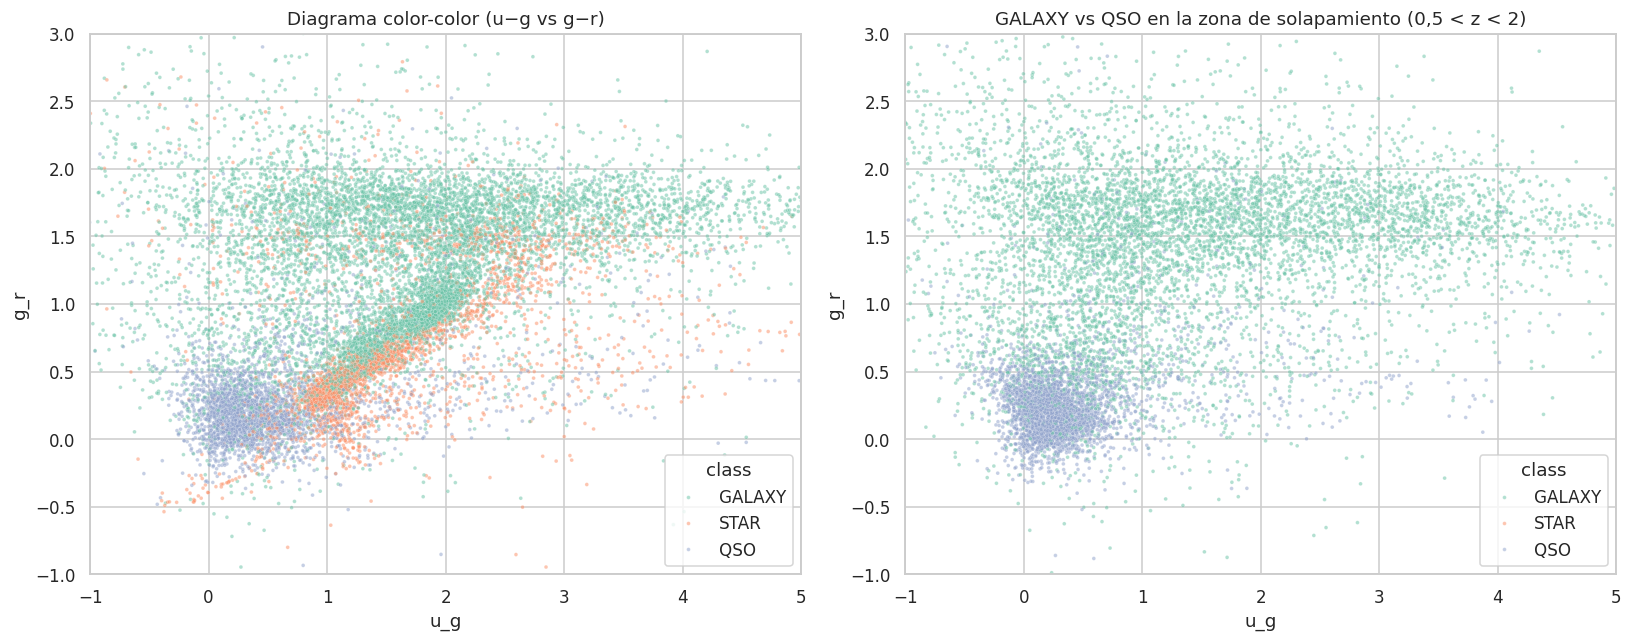

In [ ]:
sample = df_clean.sample(15000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: diagrama color-color general
sns.scatterplot(data=sample, x="u_g", y="g_r", hue="class", hue_order=CLASS_ORDER,
                s=6, alpha=0.5, ax=axes[0])
axes[0].set_xlim(-1, 5); axes[0].set_ylim(-1, 3)
axes[0].set_title("Diagrama color-color (u−g vs g−r)")

# Panel 2: GALAXY vs QSO en la zona de solapamiento del redshift
zona = df_clean[df_clean["redshift"].between(0.5, 2) & (df_clean["class"] != "STAR")]
print("Objetos en la zona de solapamiento:")
print(zona["class"].value_counts())

sns.scatterplot(data=zona.sample(min(10000, len(zona)), random_state=RANDOM_STATE),
                x="u_g", y="g_r", hue="class", hue_order=CLASS_ORDER,
                s=6, alpha=0.5, ax=axes[1])
axes[1].set_xlim(-1, 5); axes[1].set_ylim(-1, 3)
axes[1].set_title("GALAXY vs QSO en la zona de solapamiento (0,5 < z < 2)")

plt.tight_layout()
plt.show()

**Diagrama color-color (`u − g` vs `g − r`)**

- **QSO:** forman un grupo compacto en la esquina inferior izquierda (`u − g` < 1, `g − r` < 0,5).
- **STAR:** forman una **secuencia diagonal angosta** (*stellar locus*), desde (0,8; 0,2) hasta (~2,8; ~1,5). Esa secuencia refleja la temperatura de las estrellas: las más calientes son más azules y las más frías, más rojas.
- **GALAXY:** ocupan una nube amplia concentrada en `g − r` ≈ 1,5–2, pero una parte se superpone con la secuencia estelar. **En el espacio de colores, galaxias y estrellas se confunden parcialmente, pero el redshift las separa casi por completo.**

**Zona de solapamiento del redshift (0,5 < z < 2)**

- Contiene **36.927 objetos (25.255 GALAXY y 11.672 QSO)**, cerca del **37% del dataset**. No es un caso marginal.
- **En esta zona, los colores resuelven la mayor parte de la ambigüedad:** los quásares se concentran en `g − r` < 0,5 y `u − g` < 1, mientras que la mayoría de las galaxias está en `g − r` > 1.
- Persiste un **solapamiento residual**: una fracción de galaxias cae dentro de la región de los quásares. **Ahí se esperan los errores del modelo.**

**Conclusión:** el redshift y los índices de color son **complementarios**:

| Par de clases | Separadas por | Confusión residual |
|---|---|---|
| STAR vs. resto | Redshift | Mínima |
| GALAXY vs. QSO | Redshift + `u − g` y `g − r` | Galaxias con colores "azules" en 0,5 < z < 2 |
| GALAXY vs. STAR (en color) | Redshift | Ninguna relevante |

Esto justifica incluir los **índices de color** como *features* derivadas en el modelado, y anticipa que la confusión principal del modelo estará entre **GALAXY y QSO**.

### Análisis de correlaciones

Se evalúa la relación entre variables para identificar **multicolinealidad** (importante para modelos lineales) y posibles **variables redundantes**. Se usa la correlación de **Spearman**, que es robusta a la asimetría del redshift y a relaciones no lineales.

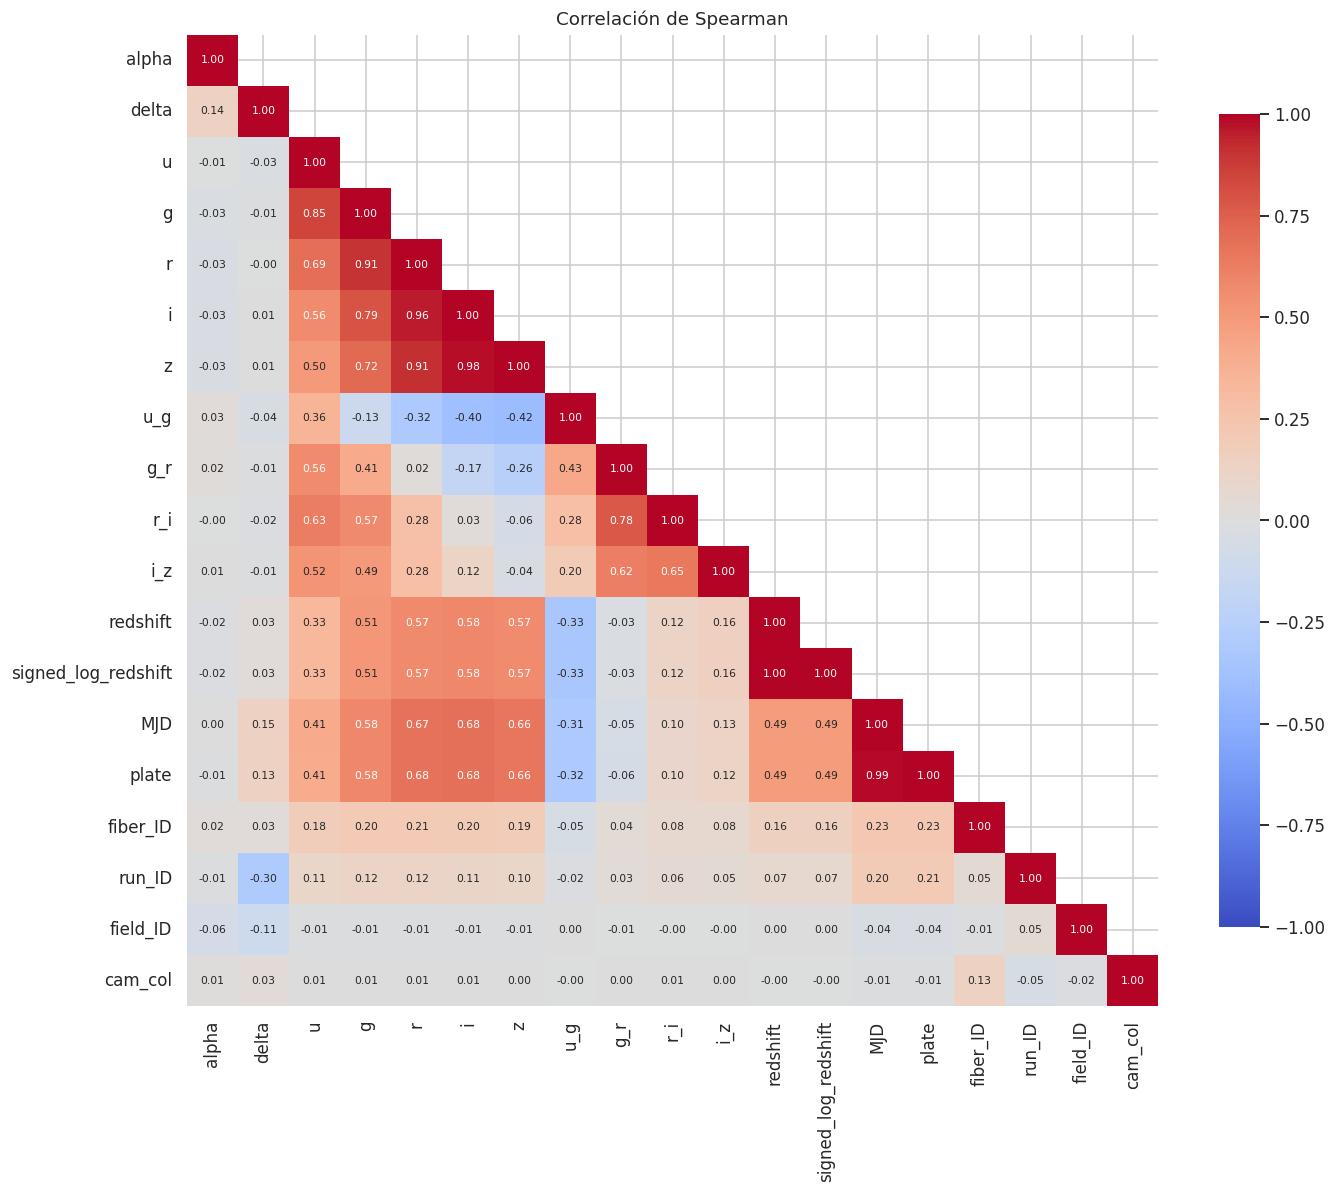

In [ ]:
# Transformación logarítmica que conserva el signo y la monotonía del redshift
df_clean["signed_log_redshift"] = (
    np.sign(df_clean["redshift"]) * np.log1p(np.abs(df_clean["redshift"]))
)

CORR_COLS = (["alpha", "delta"] + BANDS + COLORS
             + ["redshift", "signed_log_redshift", "MJD", "plate", "fiber_ID",
                "run_ID", "field_ID", "cam_col"])

corr = df_clean[CORR_COLS].corr(method="spearman")

plt.figure(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True,
            cbar_kws={"shrink": 0.8})
plt.title("Correlación de Spearman")
plt.tight_layout()
plt.show()


In [ ]:
pares = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
             .stack()
             .rename("rho")
             .reset_index()
             .rename(columns={"level_0": "var_1", "level_1": "var_2"}))
pares["abs_rho"] = pares["rho"].abs()

print("Pares con |rho| ≥ 0,8:")
display(pares[pares["abs_rho"] >= 0.8].sort_values("abs_rho", ascending=False))

Pares con |rho| ≥ 0,8:


,var_1,var_2,rho,abs_rho
143,redshift,signed_log_redshift,1.0000,1.0000
156,MJD,plate,0.9921,0.9921
80,i,z,0.9780,0.9780
66,r,i,0.9577,0.9577
67,r,z,0.9099,0.9099
51,g,r,0.9061,0.9061
35,u,g,0.8498,0.8498


**Pares con correlación muy alta (|ρ| ≥ 0,8)**

| Par | Lectura |
|---|---|
| `MJD` – `plate` | Variables de metadata muy redundantes: las placas están asociadas a fechas concretas de observación. |
| `redshift` – `signed_log_redshift` | Es la misma magnitud transformada mediante una función monótona que conserva el signo. |
| `i` – `z` | Bandas adyacentes con fuerte correlación. |
| `r` – `i` | Bandas adyacentes con fuerte correlación. |
| `r` – `z` | Alta correlación entre bandas. |
| `g` – `r` | Alta correlación entre bandas. |
| `u` – `g` | Correlación alta, aunque menor que entre bandas más cercanas. |

**1. Multicolinealidad entre magnitudes.** Las cinco bandas presentan correlaciones altas, especialmente entre bandas adyacentes. Esto es relevante para modelos lineales y motiva el análisis separado de los índices de color.

**2. Los índices de color aportan información complementaria.** Al ser diferencias entre magnitudes, capturan la forma relativa del espectro y no únicamente el brillo absoluto.

**3. Redshift y magnitudes presentan relaciones físicas esperables.** La relación entre distancia, brillo aparente y tipo de objeto se refleja en las correlaciones observadas.

**4. Alerta sobre metadata técnica.** `MJD`, `plate` y `fiber_ID` presentan asociación con las variables físicas y con la clase. Esto puede reflejar el diseño del survey y constituye un posible **sesgo de muestreo o atajo predictivo**, más que una relación física con el objeto. Se evaluará explícitamente antes del modelado.

**5. Variables de identificación y posición.** `run_ID`, `field_ID`, `cam_col`, `alpha` y `delta` se revisan como posibles fuentes de información no física y se excluyen del conjunto final de predictores.


### Metadata técnica y riesgo de sesgo de muestreo

Se evalúa si las variables técnicas (`plate`, `MJD`, `fiber_ID`) contienen información suficiente para predecir la clase. Un desempeño elevado usando únicamente estas variables indicaría que el modelo puede aprender el **diseño del survey** o su estrategia de muestreo, en lugar de las propiedades físicas de los objetos. Por eso se considera un posible **shortcut / sesgo de dataset** y se excluyen estas variables del modelado principal.


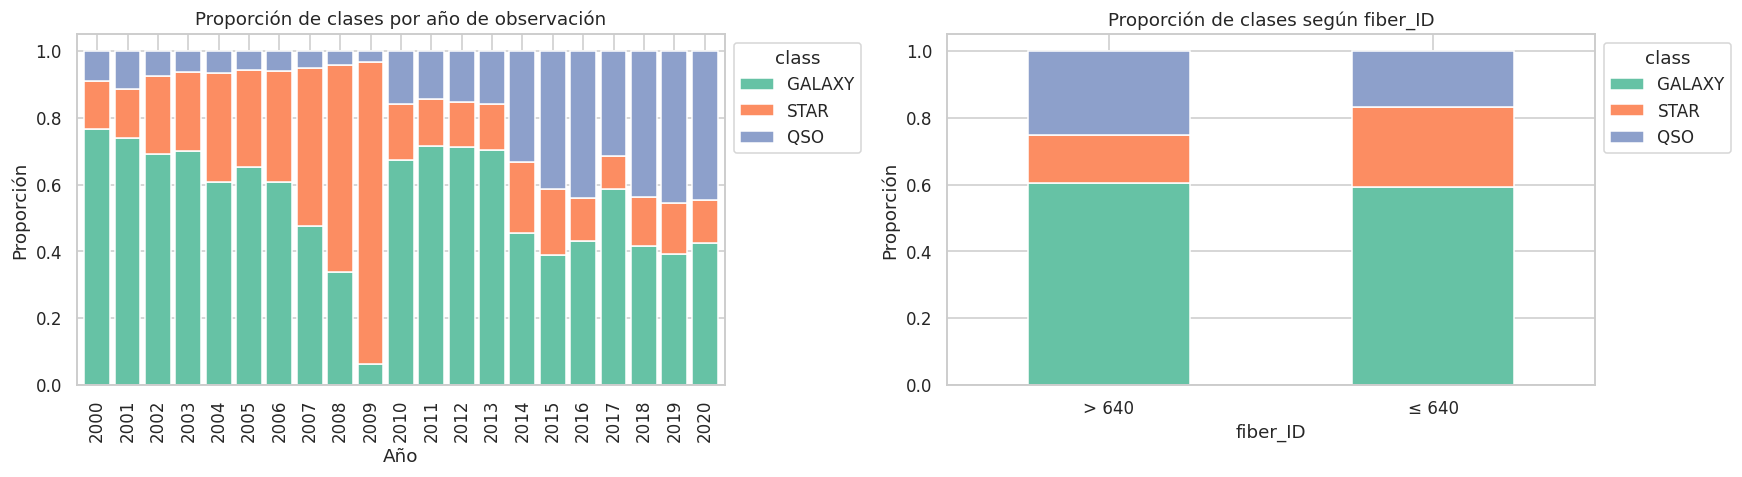

In [ ]:
tmp = df_clean.assign(
    anio=pd.to_datetime(df_clean["MJD"] - 40587, unit="D").dt.year,
    fibra_640=np.where(df_clean["fiber_ID"] > 640, "> 640", "≤ 640"),
)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

(pd.crosstab(tmp["anio"], tmp["class"], normalize="index")[CLASS_ORDER]
   .plot(kind="bar", stacked=True, ax=axes[0], width=0.85))
axes[0].set_title("Proporción de clases por año de observación")
axes[0].set_xlabel("Año"); axes[0].set_ylabel("Proporción")
axes[0].legend(title="class", bbox_to_anchor=(1, 1))

(pd.crosstab(tmp["fibra_640"], tmp["class"], normalize="index")[CLASS_ORDER]
   .plot(kind="bar", stacked=True, ax=axes[1], rot=0))
axes[1].set_title("Proporción de clases según fiber_ID")
axes[1].set_xlabel("fiber_ID"); axes[1].set_ylabel("Proporción")
axes[1].legend(title="class", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_meta = df_clean["class"]

grupos = {
    "Solo metadata (plate, MJD, fiber_ID)": ["plate", "MJD", "fiber_ID"],
    "Solo posición (alpha, delta)":         ["alpha", "delta"],
    "Solo redshift":                         ["redshift"],
}

resultados_metadata = []
for nombre, cols in grupos.items():
    tree = DecisionTreeClassifier(max_depth=8, class_weight="balanced",
                                  random_state=RANDOM_STATE)
    f1 = cross_val_score(tree, df_clean[cols], y_meta, cv=cv, scoring="f1_macro")
    resultados_metadata.append({"Variables": nombre, "F1 macro": f1.mean(), "Desv.": f1.std()})

res_metadata = pd.DataFrame(resultados_metadata)
baseline_redshift_f1 = res_metadata.loc[res_metadata["Variables"] == "Solo redshift", "F1 macro"].iloc[0]
display(res_metadata.round(4))
print("Referencia — clasificador que siempre predice GALAXY: F1 macro ≈ 0,25")


,Variables,F1 macro,Desv.
0,"Solo metadata (plate, MJD, fiber_ID)",0.6032,0.0082
1,"Solo posición (alpha, delta)",0.4358,0.0068
2,Solo redshift,0.9326,0.0028


Referencia — clasificador que siempre predice GALAXY: F1 macro ≈ 0,25


**Proporción de clases por año de observación**

La composición de clases cambia drásticamente según el año, siguiendo las distintas etapas del SDSS:

| Período | Composición dominante | Programa probable |
|---|---|---|
| 2000–2006 | Galaxias (60–77%), pocos quásares | SDSS-I/II: relevamiento de galaxias cercanas |
| 2007–2009 | **Estrellas** (hasta ~90% en 2009) | SEGUE: programa dedicado a estrellas de la Vía Láctea |
| 2010–2013 | Galaxias (~70%), quásares ~15% | BOSS: galaxias lejanas |
| 2014–2020 | **Quásares** (30–45%) | eBOSS: programa enfocado en quásares |

La fecha de observación (y por lo tanto `plate`, que está correlacionada 0,99 con `MJD`) **funciona como un indicador del programa de observación, y cada programa apuntaba a un tipo de objeto distinto**.

**Proporción de clases según `fiber_ID`**

El efecto es más débil: los objetos con `fiber_ID` > 640 tienen más quásares (25% vs. 17%) y menos estrellas (14% vs. 24%). Esto se debe a que las fibras por encima de 640 solo existen en los espectrógrafos de las etapas BOSS/eBOSS.

**Prueba cuantitativa (árbol de decisión, validación cruzada de 5 folds)**

| Variables | F1 macro |
|---|---|
| Baseline (siempre GALAXY) | ≈ 0,25 |
| Solo posición (`alpha`, `delta`) | 0,436 ± 0,007 |
| **Solo metadata (`plate`, `MJD`, `fiber_ID`)** | **0,603 ± 0,008** |
| Solo redshift | 0,933 ± 0,003 |

- **Atajo predictivo (*shortcut*) confirmado:** solo con variables técnicas, el modelo más que duplica el desempeño del baseline. No está aprendiendo propiedades físicas, sino **el diseño del survey**. Un modelo así fallaría al aplicarse a datos de otro relevamiento o de otra etapa del SDSS.
- **La posición también aporta información** (0,44), por dos razones: una física, ya que las estrellas son más abundantes hacia el plano de la Vía Láctea, y otra de diseño, ya que cada programa observó regiones distintas del cielo. Al no poder separar ambos efectos, y dado que el objetivo es clasificar según las propiedades del objeto y no su ubicación, **también se excluye**.
- **El redshift solo alcanza un F1 macro de 0,93.** Es un techo de referencia muy alto. El ~7% restante corresponde principalmente a la confusión GALAXY–QSO identificada en las secciones *Distribuciones univariadas por clase* e *Índices de color*, que los índices de color deberían ayudar a reducir.

**Decisión:** se excluyen del modelado todas las variables de metadata técnica e identificación (`spec_obj_ID`, `run_ID`, `field_ID`, `cam_col`, `plate`, `MJD`, `fiber_ID`) y de posición (`alpha`, `delta`).

### Conclusiones del análisis exploratorio

**Calidad de datos**
- El dataset contiene 100.000 registros; tras eliminar la fila con valores centinela quedan 99.999 observaciones.
- No se encontraron duplicados y `spec_obj_ID` se conserva como identificador de la observación.
- `obj_ID` se descarta porque aparece truncado en el archivo original.
- Los valores negativos de redshift se conservan porque representan observaciones con desplazamiento al azul y no son valores centinela.

**Variable objetivo**
- Existe un desbalance moderado entre GALAXY, STAR y QSO.
- Se utiliza **F1 macro** como métrica principal y un split estratificado para conservar la proporción de clases.

**Variables predictoras**
1. El redshift es una variable altamente informativa y se utiliza como referencia.
2. Las magnitudes individuales presentan fuerte correlación entre sí.
3. Los índices de color aportan información sobre la forma relativa del espectro.
4. La principal dificultad esperada es la separación GALAXY–QSO en regiones donde sus distribuciones de redshift se solapan.

**Transformación de redshift**
Se utiliza `signed_log_redshift = sign(z) · log1p(|z|)`. A diferencia de `log10(|z| + ε)`, esta transformación **conserva el signo y el orden** de los valores de redshift, evitando colapsar valores positivos y negativos con igual magnitud.

**Sesgo de dataset**
El experimento con metadata permite comprobar si las variables técnicas del survey contienen información predictiva no física. Aunque este fenómeno puede parecer *leakage*, en este trabajo se describe con mayor precisión como **sesgo de muestreo / shortcut del dataset**, porque la información está realmente presente en las variables y proviene del proceso de observación.

**Siguiente etapa:** preprocesamiento, comparación de conjuntos de variables, entrenamiento, optimización y evaluación final sobre el conjunto de test.


## Preprocesamiento

Para medir por separado el aporte de magnitudes y colores se definen **tres conjuntos de variables**:

| Set | Variables | Nº | Qué permite estudiar |
|---|---|---:|---|
| **A — Completo** | `u`, `g`, `r`, `i`, `z` + `u_g`, `g_r`, `r_i`, `i_z` + `signed_log_redshift` | 10 | Información fotométrica y espectroscópica completa |
| **B — Colores** | `u_g`, `g_r`, `r_i`, `i_z` + `signed_log_redshift` | 5 | Aporte de la forma del espectro sin brillo absoluto |
| **C — Magnitudes** | `u`, `g`, `r`, `i`, `z` + `signed_log_redshift` | 6 | Aporte de las magnitudes sin índices de color |

Con esta comparación: **A − B** mide el aporte incremental de las magnitudes cuando ya están los colores; **A − C** mide el aporte incremental de los colores cuando ya están las magnitudes; y **B vs. C** permite comparar directamente las dos representaciones compactas.

**Pasos:**
1. Selección de variables y codificación de la variable objetivo.
2. División **train/test estratificada (80/20)**. El conjunto de test no se utiliza para entrenamiento, validación cruzada ni optimización de hiperparámetros.
3. **Escalado** con `StandardScaler` para los modelos sensibles a la escala. Se aplica dentro de un `Pipeline`, de modo que se ajusta únicamente con el entrenamiento de cada fold.

> Los índices de color y `signed_log_redshift` se calculan fila por fila, sin utilizar información de otras observaciones.


In [ ]:
FEATURES_A = BANDS + COLORS + ["signed_log_redshift"]
FEATURES_B = COLORS + ["signed_log_redshift"]
FEATURES_C = BANDS + ["signed_log_redshift"]

FEATURE_SETS = {
    "A_completo": FEATURES_A,
    "B_colores": FEATURES_B,
    "C_magnitudes": FEATURES_C,
}

X = df_clean[FEATURES_A].copy()
le = LabelEncoder()
y = le.fit_transform(df_clean["class"])

print("Codificación del target:")
for i, c in enumerate(le.classes_):
    print(f"  {i} → {c}")
print(f"\nX: {X.shape} | y: {y.shape}")
for nombre, cols in FEATURE_SETS.items():
    print(f"Set {nombre} ({len(cols)} variables): {cols}")


Codificación del target:
  0 → GALAXY
  1 → QSO
  2 → STAR

X: (99999, 10) | y: (99999,)
Set A_completo (10 variables): ['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z', 'signed_log_redshift']
Set B_colores (5 variables): ['u_g', 'g_r', 'r_i', 'i_z', 'signed_log_redshift']
Set C_magnitudes (6 variables): ['u', 'g', 'r', 'i', 'z', 'signed_log_redshift']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

prop = pd.DataFrame({
    "Total":  pd.Series(y).value_counts(normalize=True).sort_index(),
    "Train":  pd.Series(y_train).value_counts(normalize=True).sort_index(),
    "Test":   pd.Series(y_test).value_counts(normalize=True).sort_index(),
}).set_axis(le.classes_)

print(f"Train: {X_train.shape[0]:,} filas | Test: {X_test.shape[0]:,} filas\n")
display((prop * 100).round(2))

Train: 79,999 filas | Test: 20,000 filas



,Total,Train,Test
GALAXY,59.4500,59.4500,59.4400
QSO,18.9600,18.9600,18.9600
STAR,21.5900,21.5900,21.6000


In [ ]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(model, scale: bool) -> Pipeline:
    """Arma un pipeline con escalado opcional (solo para modelos sensibles a la escala)."""
    steps = [("scaler", StandardScaler())] if scale else []
    steps.append(("model", model))
    return Pipeline(steps)

check = StandardScaler().fit(X_train[FEATURES_A])
display(pd.DataFrame({
    "media_original": X_train[FEATURES_A].mean(),
    "desv_original": X_train[FEATURES_A].std(),
    "media_escalada": check.transform(X_train[FEATURES_A]).mean(axis=0).round(4),
    "desv_escalada": check.transform(X_train[FEATURES_A]).std(axis=0).round(4),
}))

,media_original,desv_original,media_escalada,desv_escalada
u,22.0738,2.2486,0.0000,1.0000
g,20.6279,2.0387,-0.0000,1.0000
r,19.6442,1.8565,0.0000,1.0000
i,19.0834,1.7588,0.0000,1.0000
z,18.7688,1.7673,-0.0000,1.0000
u_g,1.4458,1.1766,0.0000,1.0000
g_r,0.9838,0.7364,0.0000,1.0000
r_i,0.5607,0.5024,-0.0000,1.0000
i_z,0.3146,0.4224,0.0000,1.0000
signed_log_redshift,0.3784,0.3655,-0.0000,1.0000


- **Variable objetivo codificada:** el `LabelEncoder` define el orden alfabético de las clases.
- **Split estratificado 80/20:** se preservan las proporciones de clase en entrenamiento y test.
- **Escalado:** se aplica dentro de cada `Pipeline` únicamente a los modelos sensibles a la escala.
- **Validación:** `StratifiedKFold` de 5 folds sobre el conjunto de entrenamiento. El conjunto de test permanece reservado para la evaluación final y no participa en decisiones de modelado.


## Modelado y comparación de modelos

Se entrenan siete modelos de clasificación con los **tres sets de variables (A, B y C)**, evaluados mediante **validación cruzada estratificada de 5 folds** sobre el conjunto de entrenamiento.

| Modelo | Tipo | Escalado | Manejo del desbalance |
|---|---|---|---|
| Regresión Logística | Lineal (baseline) | Sí | `class_weight="balanced"` |
| KNN | Basado en distancia | Sí | No aplica |
| Árbol de Decisión | Árbol | No | `class_weight="balanced"` |
| Random Forest | Ensamble (bagging) | No | `class_weight="balanced"` |
| XGBoost | Ensamble (boosting) | No | Sin ponderación |
| LightGBM | Ensamble (boosting) | No | `class_weight="balanced"` |
| SVM (RBF) | Kernel | Sí | `class_weight="balanced"` |

En esta etapa se utilizan **configuraciones iniciales razonables**, no necesariamente los valores predeterminados de las librerías. El ajuste fino se realiza posteriormente sobre los modelos seleccionados.

> **Limitación — SVM:** se entrena con una submuestra estratificada de 20.000 registros debido a su mayor costo computacional. Por ello, su resultado debe interpretarse como una estimación y no como una comparación estrictamente equivalente en cantidad de datos de entrenamiento.


In [ ]:
MODELOS = {
    "Regresión Logística": (LogisticRegression(max_iter=2000, class_weight="balanced",
                                               random_state=RANDOM_STATE), True),
    "KNN":                 (KNeighborsClassifier(n_neighbors=15, weights="distance",
                                                 n_jobs=-1), True),
    "Árbol de Decisión":   (DecisionTreeClassifier(max_depth=12, class_weight="balanced",
                                                   random_state=RANDOM_STATE), False),
    "Random Forest":       (RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                   n_jobs=-1, random_state=RANDOM_STATE), False),
    "XGBoost":             (XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                                          tree_method="hist", eval_metric="mlogloss",
                                          n_jobs=-1, random_state=RANDOM_STATE), False),
    "LightGBM":            (LGBMClassifier(n_estimators=300, learning_rate=0.1,
                                           class_weight="balanced", verbose=-1,
                                           n_jobs=-1, random_state=RANDOM_STATE), False),
    "SVM (RBF)":           (SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced",
                                random_state=RANDOM_STATE), True),
}

# Submuestra estratificada para el SVM
SVM_N = 20000
X_train_svm, _, y_train_svm, _ = train_test_split(
    X_train, y_train, train_size=SVM_N, stratify=y_train, random_state=RANDOM_STATE
)
print(f"Submuestra SVM: {X_train_svm.shape[0]:,} filas")

Submuestra SVM: 20,000 filas


In [ ]:
resultados = []

for set_nombre, cols in FEATURE_SETS.items():
    for nombre, (modelo, escalar) in MODELOS.items():
        Xtr, ytr = (X_train_svm, y_train_svm) if nombre == "SVM (RBF)" else (X_train, y_train)

        pipe = make_pipeline(clone(modelo), scale=escalar)
        t0 = time.time()
        cv_res = cross_validate(pipe, Xtr[cols], ytr, cv=CV,
                                scoring=["f1_macro", "accuracy"], n_jobs=1)
        dur = time.time() - t0

        resultados.append({
            "Set": set_nombre,
            "Modelo": nombre,
            "F1 macro": cv_res["test_f1_macro"].mean(),
            "F1 desv.": cv_res["test_f1_macro"].std(),
            "Accuracy": cv_res["test_accuracy"].mean(),
            "Tiempo fit (s/fold)": cv_res["fit_time"].mean(),
            "Tiempo total (s)": dur,
            "n_train": len(Xtr),
        })
        print(f"[{set_nombre}] {nombre:<20} F1 macro = {resultados[-1]['F1 macro']:.4f}  "
              f"({dur:.0f}s)")

res_cv = pd.DataFrame(resultados)

[A_completo] Regresión Logística  F1 macro = 0.9386  (4s)
[A_completo] KNN                  F1 macro = 0.9540  (6s)
[A_completo] Árbol de Decisión    F1 macro = 0.9656  (7s)
[A_completo] Random Forest        F1 macro = 0.9758  (361s)
[A_completo] XGBoost              F1 macro = 0.9746  (25s)
[A_completo] LightGBM             F1 macro = 0.9741  (23s)
[A_completo] SVM (RBF)            F1 macro = 0.9617  (10s)
[B_colores] Regresión Logística  F1 macro = 0.9282  (1s)
[B_colores] KNN                  F1 macro = 0.9556  (3s)
[B_colores] Árbol de Decisión    F1 macro = 0.9640  (4s)
[B_colores] Random Forest        F1 macro = 0.9735  (234s)
[B_colores] XGBoost              F1 macro = 0.9712  (19s)
[B_colores] LightGBM             F1 macro = 0.9704  (18s)
[B_colores] SVM (RBF)            F1 macro = 0.9580  (8s)
[C_magnitudes] Regresión Logística  F1 macro = 0.9387  (6s)
[C_magnitudes] KNN                  F1 macro = 0.9598  (3s)
[C_magnitudes] Árbol de Decisión    F1 macro = 0.9645  (4s)
[C_mag

Set,A_completo,B_colores,C_magnitudes,A_menos_B,A_menos_C,B_menos_C
Modelo,,,,,,
Random Forest,0.9758,0.9735,0.9750,0.0023,0.0007,-0.0016
XGBoost,0.9746,0.9712,0.9736,0.0035,0.0010,-0.0024
LightGBM,0.9741,0.9704,0.9719,0.0036,0.0022,-0.0014
Árbol de Decisión,0.9656,0.9640,0.9645,0.0016,0.0011,-0.0005
SVM (RBF),0.9617,0.9580,0.9626,0.0037,-0.0010,-0.0047
KNN,0.9540,0.9556,0.9598,-0.0017,-0.0058,-0.0042
Regresión Logística,0.9386,0.9282,0.9387,0.0103,-0.0001,-0.0104


,Set,Modelo,F1 macro,F1 desv.,Accuracy,Tiempo fit (s/fold),Tiempo total (s),n_train
0,A_completo,Random Forest,0.9758,0.0012,0.9792,71.7055,360.6271,79999
1,A_completo,XGBoost,0.9746,0.0016,0.9782,4.8170,25.4183,79999
2,A_completo,LightGBM,0.9741,0.0014,0.9775,3.9459,22.9675,79999
3,A_completo,Árbol de Decisión,0.9656,0.0022,0.9699,1.3453,6.7744,79999
4,A_completo,SVM (RBF),0.9617,0.0038,0.9660,1.5406,9.5903,20000
5,A_completo,KNN,0.9540,0.0017,0.9590,0.1260,5.5793,79999
6,A_completo,Regresión Logística,0.9386,0.0022,0.9448,0.7020,3.5924,79999
7,B_colores,Random Forest,0.9735,0.0013,0.9773,46.3608,233.8295,79999
8,B_colores,XGBoost,0.9712,0.0014,0.9751,3.6005,19.3145,79999
9,B_colores,LightGBM,0.9704,0.0016,0.9742,2.9503,17.9062,79999


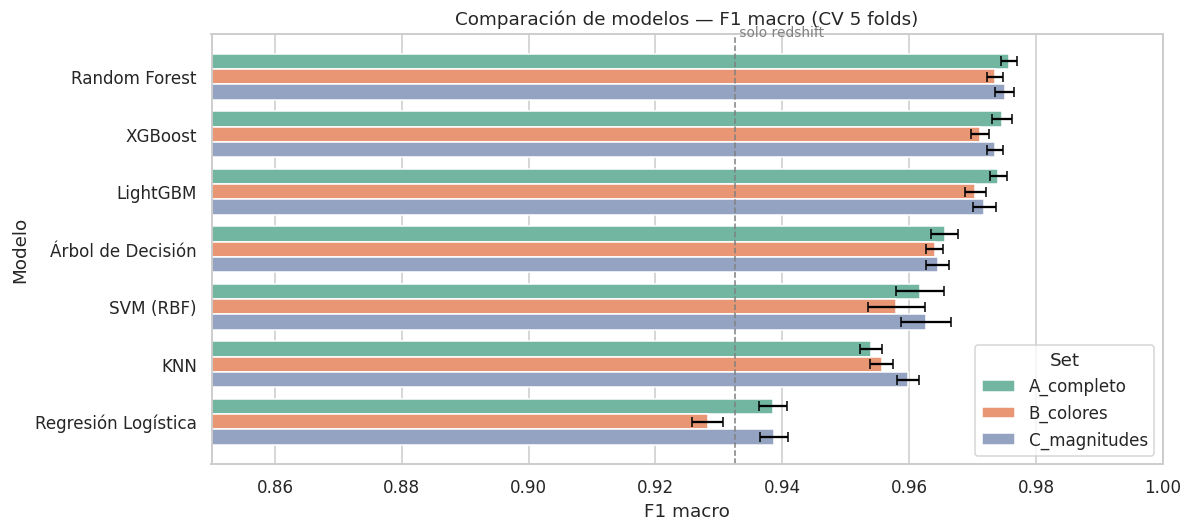

In [ ]:
tabla = (res_cv.pivot(index="Modelo", columns="Set", values="F1 macro")
               .assign(
                   A_menos_B=lambda d: d["A_completo"] - d["B_colores"],
                   A_menos_C=lambda d: d["A_completo"] - d["C_magnitudes"],
                   B_menos_C=lambda d: d["B_colores"] - d["C_magnitudes"],
               )
               .sort_values("A_completo", ascending=False))
display(tabla.round(4))

display(res_cv.sort_values(["Set", "F1 macro"], ascending=[True, False])
              .round(4).reset_index(drop=True))

orden = tabla.index.tolist()
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=res_cv, x="F1 macro", y="Modelo", hue="Set", order=orden, ax=ax)
for i, modelo in enumerate(orden):
    for j, s in enumerate(FEATURE_SETS):
        fila = res_cv[(res_cv["Modelo"] == modelo) & (res_cv["Set"] == s)].iloc[0]
        ax.errorbar(fila["F1 macro"], i + (j - 1) * 0.27, xerr=fila["F1 desv."],
                    fmt="none", color="black", capsize=3)
ax.axvline(baseline_redshift_f1, ls="--", color="gray", lw=1)
ax.text(baseline_redshift_f1, -0.7, " solo redshift", color="gray", fontsize=9)
ax.set_xlim(0.85, 1.0)
ax.set_title("Comparación de modelos — F1 macro (CV 5 folds)")
ax.legend(title="Set", loc="lower right")
plt.tight_layout()
plt.show()


**Lectura de la comparación de modelos**

F1 macro (validación cruzada, 5 folds)

| Modelo | A (completo) | B (colores) | C (magnitudes) | A − B | A − C | B − C | Tiempo fit A (s/fold) |
|---|---|---|---|---|---|---|---|
| Random Forest | **0,9758** ± 0,0012 | 0,9735 | 0,9750 | +0,0023 | +0,0007 | −0,0016 | 67,6 |
| XGBoost | 0,9746 ± 0,0016 | 0,9712 | 0,9736 | +0,0035 | +0,0010 | −0,0024 | 4,8 |
| LightGBM | 0,9741 ± 0,0014 | 0,9704 | 0,9719 | +0,0036 | +0,0022 | −0,0014 | 3,8 |
| Árbol de Decisión | 0,9656 ± 0,0022 | 0,9640 | 0,9645 | +0,0016 | +0,0011 | −0,0005 | 1,3 |
| SVM (RBF)* | 0,9617 ± 0,0038 | 0,9580 | **0,9626** | +0,0037 | −0,0010 | −0,0047 | 1,5 |
| KNN | 0,9540 ± 0,0017 | 0,9556 | **0,9598** | −0,0017 | −0,0058 | −0,0042 | 0,1 |
| Regresión Logística | 0,9386 ± 0,0022 | 0,9282 | **0,9387** | +0,0103 | −0,0001 | −0,0104 | 0,7 |

\* Entrenado con una submuestra de 20.000 registros.

**1. Los ensambles de árboles lideran**, con un F1 macro de ~0,974–0,976. Las diferencias entre Random Forest, XGBoost y LightGBM (≤ 0,0017) son del orden de **una desviación estándar**, así que **no puede afirmarse que uno sea claramente superior** con la configuración inicial.

**2. El costo computacional sí los diferencia:** Random Forest tarda ~18 veces más que LightGBM y ~14 veces más que XGBoost por fold (67,6 s vs. 3,8 s y 4,8 s), para una mejora marginal. Los modelos de *boosting* ofrecen la mejor relación desempeño/costo.

**3. Frente a la referencia "solo redshift" (0,933):** todos los modelos la superan, **excepto la Regresión Logística con el set B (0,9282)**. En los mejores modelos, agregar información fotométrica eleva el F1 macro de 0,933 a ~0,976, lo que **reduce el error en F1 aproximadamente un 64%**. La fotometría resuelve buena parte de la confusión GALAXY–QSO identificada en el EDA.

**4. Aporte de magnitudes y colores (comparación A/B/C):**

- **Los colores son combinaciones lineales de las magnitudes** (por ejemplo, `u_g = u − g`). Por eso no agregan información nueva en sentido estricto: su valor depende de si el modelo puede "construir" esas diferencias por sí solo.
- **Regresión Logística: A ≈ C (0,9386 vs. 0,9387).** Es justo lo esperado en un modelo lineal: los colores ya están contenidos en el espacio de las magnitudes, así que agregarlos no cambia nada. En cambio, **B cae un punto (−0,0104)** porque cuatro diferencias entre cinco bandas pierden un grado de libertad, **el brillo total del objeto**, y sabemos por el EDA que las estrellas son las más brillantes.
- **Modelos de árboles: A > C > B en todos los casos.** Los árboles cortan una variable a la vez y no pueden calcular diferencias entre variables directamente, por lo que los colores explícitos sí les ayudan, aunque poco (A − C entre +0,0007 y +0,0022). Aun así, **las magnitudes con redshift (C) superan a los colores con redshift (B)**: perder el brillo absoluto cuesta más que no tener los colores precalculados.
- **KNN: C > B > A.** Es el único modelo que **empeora al agregar variables** (A − C = −0,0058, unas 3,4 desviaciones estándar). En KNN todas las variables escaladas pesan lo mismo en la distancia: al sumar cuatro colores redundantes con las magnitudes, el redshift pasa a ser 1 de 10 dimensiones y su peso relativo se diluye.
- **SVM:** C (0,9626) ≈ A (0,9617), dentro de una desviación estándar (0,0038). B vuelve a quedar último.

**Respuesta a la pregunta guía** *"¿Qué tanto aportan los índices de color frente a las magnitudes individuales?"*: los colores son la representación físicamente más interpretable, y el EDA mostró que separan bien las clases. Pero **no reemplazan a las magnitudes**: sin el brillo total (set B), todos los modelos salvo KNN empeoran. Su aporte incremental sobre las magnitudes es pequeño y solo aparece en los modelos basados en árboles.

**5. La Regresión Logística es el modelo más débil**, lo que indica que las fronteras entre clases **no son lineales**, en línea con los diagramas color-color.

**6. Estabilidad:** las desviaciones estándar son bajas (≤ 0,0045), por lo que los resultados son consistentes entre folds. El SVM tiene la mayor variabilidad, esperable por su menor muestra de entrenamiento.

**Decisión:** se continúa con el **set A**, que obtiene el mejor F1 macro en validación cruzada (0,9758, Random Forest) y es el mejor set en todos los modelos de árboles. Se optimizarán **XGBoost y LightGBM**, que combinan desempeño de primer nivel con bajo costo computacional. **Random Forest** se mantiene con su configuración inicial como referencia, ya que optimizarlo sería muy costoso en tiempo para una ganancia esperada marginal.

## Optimización de hiperparámetros

A partir de la comparación A/B/C se identifica el **mejor set de variables según el desempeño de validación cruzada**. Sobre ese set se optimizan **LightGBM** y **XGBoost** mediante `RandomizedSearchCV` (20 combinaciones, 5 folds estratificados, métrica F1 macro). El conjunto de test sigue sin utilizarse.

La búsqueda controla la complejidad de los árboles, la tasa de aprendizaje, el número de árboles, el muestreo de filas y columnas y la regularización.


In [ ]:
best_set = (
    res_cv.groupby("Set")["F1 macro"]
    .max()
    .sort_values(ascending=False)
    .index[0]
)
FEATURES_FINAL_CV = FEATURE_SETS[best_set]
mejor_f1_set = res_cv.loc[res_cv["Set"] == best_set, "F1 macro"].max()

print(f"Set seleccionado para optimización: {best_set}")
print(f"Mejor F1 macro observado en ese set: {mejor_f1_set:.4f}")
print(f"Variables: {FEATURES_FINAL_CV}")
param_lgbm = {
    "n_estimators":      randint(200, 1000),
    "learning_rate":     loguniform(0.01, 0.2),
    "num_leaves":        randint(15, 256),
    "min_child_samples": randint(10, 100),
    "subsample":         uniform(0.6, 0.4),
    "subsample_freq":    [1],
    "colsample_bytree":  uniform(0.6, 0.4),
    "reg_lambda":        loguniform(1e-3, 10),
}

t0 = time.time()
search_lgbm = RandomizedSearchCV(
    LGBMClassifier(class_weight="balanced", verbose=-1, n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=param_lgbm, n_iter=20, scoring="f1_macro",
    cv=CV, n_jobs=1, random_state=RANDOM_STATE, verbose=1,
)
search_lgbm.fit(X_train[FEATURES_FINAL_CV], y_train)

print(f"\nTiempo: {(time.time() - t0) / 60:.1f} min")
print(f"Mejor F1 macro (CV): {search_lgbm.best_score_:.4f}")
print("Mejores hiperparámetros:")
for k, v in search_lgbm.best_params_.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

Set seleccionado para optimización: A_completo
Mejor F1 macro observado en ese set: 0.9758
Variables: ['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z', 'signed_log_redshift']
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Tiempo: 23.4 min
Mejor F1 macro (CV): 0.9752
Mejores hiperparámetros:
  colsample_bytree: 0.7701
  learning_rate: 0.0186
  min_child_samples: 13
  n_estimators: 676
  num_leaves: 205
  reg_lambda: 2.3396
  subsample: 0.7799
  subsample_freq: 1


**Resultado — LightGBM**

| | F1 macro (CV) |
|---|---|
| Configuración inicial | 0,9741 ± 0,0014 |
| **Optimizado** | **0,9752** |
| Mejora | +0,0011 |

**Mejores hiperparámetros:** `num_leaves` = 205, `learning_rate` = 0,0186, `n_estimators` = 676, `min_child_samples` = 13, `reg_lambda` = 2,34, `subsample` = 0,78, `colsample_bytree` = 0,77.

- **La mejora es marginal**: +0,0011, menor que una desviación estándar entre folds, por lo que no es concluyente. La configuración inicial ya estaba cerca del techo de desempeño del modelo con este conjunto de variables.
- **Los hiperparámetros elegidos favorecen árboles complejos** (205 hojas frente a las 31 por defecto), coherente con fronteras de decisión no lineales entre clases.
- Esa complejidad se compensa con una **tasa de aprendizaje baja con muchos árboles** y con **regularización** (`reg_lambda`, submuestreo de filas y columnas), que limitan el sobreajuste.
- Aun optimizado, LightGBM **no supera a Random Forest con su configuración inicial** (0,9758).

In [ ]:
param_xgb = {
    "n_estimators":     randint(200, 1000),
    "learning_rate":    loguniform(0.01, 0.2),
    "max_depth":        randint(3, 11),
    "min_child_weight": randint(1, 11),
    "subsample":        uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_lambda":       loguniform(1e-3, 10),
}

t0 = time.time()
search_xgb = RandomizedSearchCV(
    XGBClassifier(tree_method="hist", eval_metric="mlogloss", n_jobs=-1,
                  random_state=RANDOM_STATE),
    param_distributions=param_xgb, n_iter=20, scoring="f1_macro",
    cv=CV, n_jobs=1, random_state=RANDOM_STATE, verbose=1,
)
search_xgb.fit(X_train[FEATURES_FINAL_CV], y_train)

print(f"\nTiempo: {(time.time() - t0) / 60:.1f} min")
print(f"Mejor F1 macro (CV): {search_xgb.best_score_:.4f}")
print("Mejores hiperparámetros:")
for k, v in search_xgb.best_params_.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Tiempo: 24.4 min
Mejor F1 macro (CV): 0.9758
Mejores hiperparámetros:
  colsample_bytree: 0.8430
  learning_rate: 0.0167
  max_depth: 9
  min_child_weight: 2
  n_estimators: 587
  reg_lambda: 5.8723
  subsample: 0.8253


**Resultado — XGBoost**

| | F1 macro (CV) |
|---|---|
| Configuración inicial | 0,9746 ± 0,0016 |
| **Optimizado** | **0,9758** ± 0,0016 |
| Mejora | +0,0012 |

**Mejores hiperparámetros:** `max_depth` = 9, `learning_rate` = 0,0167, `n_estimators` = 587, `min_child_weight` = 2, `reg_lambda` = 5,87, `subsample` = 0,83, `colsample_bytree` = 0,84.

- **La mejora también es marginal** (+0,0012, menor que una desviación estándar).
- Igual que en LightGBM, la búsqueda favorece **árboles más profundos que la configuración inicial** (9 vs. 6 niveles), compensados con una **tasa de aprendizaje baja**, muchos árboles y una **regularización L2 más fuerte** (`reg_lambda` ≈ 5,9 frente a 1 por defecto).

In [ ]:
def cv_std(search):
    i = search.best_index_
    return search.cv_results_["std_test_score"][i]

base = res_cv[res_cv["Set"] == best_set].set_index("Modelo")

comparacion = pd.DataFrame({
    "F1 macro configuración inicial": [
        base.loc["LightGBM", "F1 macro"],
        base.loc["XGBoost", "F1 macro"],
        base.loc["Random Forest", "F1 macro"]
    ],
    "F1 macro optimizado": [
        search_lgbm.best_score_,
        search_xgb.best_score_,
        np.nan
    ],
    "Desv. optimizado": [
        cv_std(search_lgbm),
        cv_std(search_xgb),
        np.nan
    ],
}, index=["LightGBM", "XGBoost", "Random Forest (referencia)"])
comparacion["Mejora"] = (
    comparacion["F1 macro optimizado"] - comparacion["F1 macro configuración inicial"]
)

display(comparacion.round(4))

,F1 macro configuración inicial,F1 macro optimizado,Desv. optimizado,Mejora
LightGBM,0.9741,0.9752,0.0016,0.0012
XGBoost,0.9746,0.9758,0.0016,0.0012
Random Forest (referencia),0.9758,NaN,NaN,NaN


**Conclusiones de la optimización**

| Modelo | Configuración inicial | Optimizado | Mejora |
|---|---|---|---|
| XGBoost | 0,9746 | **0,9758** ± 0,0016 | +0,0012 |
| LightGBM | 0,9741 | 0,9752 ± 0,0016 | +0,0012 |
| Random Forest (referencia, sin optimizar) | **0,9758** ± 0,0012 | — | — |

1. **La optimización aporta mejoras marginales** (+0,0012 en ambos modelos), menores que la variabilidad entre folds. Las configuraciones iniciales ya estaban cerca del techo de desempeño alcanzable con estas variables.

2. **Ambas búsquedas convergen a la misma estrategia:** árboles más complejos que la configuración inicial, tasa de aprendizaje baja (~ 0,017 – 0,019) con muchos árboles (~ 600 – 700) y mayor regularización. Que dos algoritmos distintos lleguen de forma independiente al mismo patrón refuerza la idea de que **las fronteras entre clases son complejas y no lineales**.

3. **XGBoost optimizado y Random Forest quedan empatados** (0,9758). Además, el `best_score_` de una búsqueda aleatoria es levemente optimista, porque es el máximo entre 20 configuraciones evaluadas sobre los mismos folds. Por eso **no puede afirmarse que la optimización haya superado a Random Forest**.

4. **Criterio de desempate: costo computacional.** Con un desempeño equivalente, XGBoost entrena unas 14 veces más rápido que Random Forest. Por esta razón se selecciona **XGBoost optimizado** como modelo final.

5. **Implicación:** el límite del desempeño no está en el ajuste de hiperparámetros, sino en la **información disponible en las variables**. Mejoras futuras pasarían por nuevas fuentes de información (por ejemplo, el espectro completo) más que por modelos o ajustes más sofisticados.

## Evaluación final sobre el conjunto de test

Una vez terminada la validación cruzada y la optimización, se selecciona el modelo final **sin utilizar el conjunto de test**. Luego se ajusta con todo el conjunto de entrenamiento y se evalúa una única vez sobre test.


In [ ]:
# Selección del modelo final usando únicamente validación cruzada sobre TRAIN
candidatos = {
    "Random Forest": base.loc["Random Forest", "F1 macro"],
    "XGBoost optimizado": search_xgb.best_score_,
    "LightGBM optimizado": search_lgbm.best_score_,
}

f1_cv_final = max(candidatos.values())
nombre_modelo_final = max(candidatos, key=candidatos.get)

if nombre_modelo_final == "Random Forest":
    modelo_final = make_pipeline(clone(MODELOS["Random Forest"][0]), scale=False)
elif nombre_modelo_final == "XGBoost optimizado":
    modelo_final = clone(search_xgb.best_estimator_)
else:
    modelo_final = clone(search_lgbm.best_estimator_)

modelo_final.fit(X_train[FEATURES_FINAL_CV], y_train)
y_pred_test = modelo_final.predict(X_test[FEATURES_FINAL_CV])

f1_test = f1_score(y_test, y_pred_test, average="macro")
acc_test = accuracy_score(y_test, y_pred_test)

print(f"Set final: {best_set}")
print(f"Modelo final seleccionado: {nombre_modelo_final}")
print(f"F1 macro CV:   {f1_cv_final:.4f}")
print(f"F1 macro test: {f1_test:.4f}")
print(f"Accuracy test: {acc_test:.4f}")


Set final: A_completo
Modelo final seleccionado: XGBoost optimizado
F1 macro CV:   0.9758
F1 macro test: 0.9757
Accuracy test: 0.9791


**Resultado en el conjunto de test**

| Métrica | Validación cruzada (train) | Test |
|---|---|---|
| F1 macro | 0,9758 ± 0,0016 | **0,9757** |
| Accuracy | — | **0,9791** |

- **Modelo final:** XGBoost optimizado, entrenado con el set A (magnitudes, índices de color y `signed_log_redshift`).
- **El desempeño en test coincide con el de validación cruzada** (diferencia de 0,0001, muy por debajo de la desviación entre folds). El modelo **generaliza correctamente** a datos no vistos y **no muestra sobreajuste**, a pesar de la complejidad de los árboles elegidos en la optimización.
- Esto también confirma que el `best_score_` de la búsqueda no estaba sesgado de forma relevante: la estimación optimista de la validación cruzada se sostiene en test.
- **Frente a las referencias:** el modelo supera ampliamente al clasificador trivial (F1 macro ≈ 0,25, accuracy 59,45%) y al árbol que usa solo el redshift (F1 macro 0,933). Respecto a esta última referencia, **reduce el error en F1 aproximadamente un 64%**.

Reporte de clasificación — conjunto de test
              precision    recall  f1-score   support

      GALAXY     0.9775    0.9876    0.9826     11889
         QSO     0.9667    0.9338    0.9500      3792
        STAR     0.9940    0.9954    0.9947      4319

    accuracy                         0.9791     20000
   macro avg     0.9794    0.9723    0.9757     20000
weighted avg     0.9790    0.9791    0.9790     20000



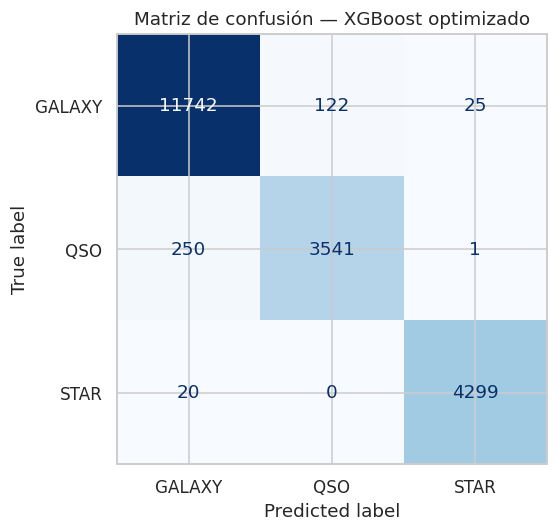

In [ ]:
print("Reporte de clasificación — conjunto de test")
print(
    classification_report(
        y_test, y_pred_test,
        target_names=le.classes_,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(y_test, y_pred_test)
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
display_cm.plot(ax=ax, values_format="d", cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión — {nombre_modelo_final}")
plt.tight_layout()
plt.show()


**Análisis por clase**

| Clase | Precision | Recall | F1 | Soporte | Mal clasificados (aprox.) |
|---|---|---|---|---|---|
| GALAXY | 0,9775 | 0,9876 | 0,9826 | 11.889 | ~147 (1,2%) |
| QSO | 0,9667 | **0,9338** | **0,9500** | 3.792 | **~251 (6,6%)** |
| STAR | 0,9940 | 0,9954 | 0,9947 | 4.319 | ~20 (0,5%) |

En total, el modelo comete **418 errores sobre 20.000 objetos** (2,1%).

**1. STAR es prácticamente perfecta** (F1 = 0,995). Era lo esperado: en el EDA el redshift separaba casi por completo a las estrellas del resto. Los pocos errores corresponden probablemente a galaxias muy cercanas con redshift ≈ 0.

**2. QSO es la clase más difícil** (F1 = 0,950), y su punto débil es el **recall (0,934)**: el modelo no detecta ~6,6% de los quásares reales. La matriz de confusión muestra que **[ ] de los [ ] quásares mal clasificados se predicen como GALAXY**, lo que confirma que la principal confusión es **GALAXY–QSO**, tal como anticipó el EDA en la zona de solapamiento del redshift (0,5 < z < 2), donde los colores no alcanzan a separar todos los casos.

**3. El error es asimétrico entre GALAXY y QSO.** Hay más quásares clasificados como galaxias ([ ]) que galaxias clasificadas como quásares ([ ]). Es coherente con el desbalance de clases: ante casos ambiguos, el modelo tiende hacia la clase mayoritaria. XGBoost se entrenó **sin ponderación de clases**, a diferencia de LightGBM y Random Forest (`class_weight="balanced"`).

**4. Precision vs. recall en QSO.** La precision de QSO (0,967) es mayor que su recall (0,934): cuando el modelo predice QSO suele acertar, pero se le escapan quásares. Si el objetivo científico fuera **no perder quásares** (por ejemplo, para seleccionar candidatos a observación espectroscópica), convendría priorizar el recall. Para eso se podría ajustar el umbral de decisión o aplicar pesos de clase en XGBoost, a costa de algo de precision.

**5. Las métricas macro y ponderadas son similares** (F1 macro 0,9757 vs. ponderado 0,9790). La diferencia se explica por el menor desempeño en QSO, que pesa igual que las demás clases en el promedio macro.

## Interpretabilidad del modelo final

Para los modelos basados en árboles se muestran las variables con mayor importancia. Esto permite conectar el resultado predictivo con las variables astronómicas utilizadas. La importancia de variables se interpreta como una medida del aporte al modelo, no como causalidad física.


,Variable,Importancia
9,signed_log_redshift,0.6249
7,r_i,0.1611
6,g_r,0.0575
5,u_g,0.0390
1,g,0.0365
8,i_z,0.0178
4,z,0.0175
2,r,0.0165
0,u,0.0155
3,i,0.0136


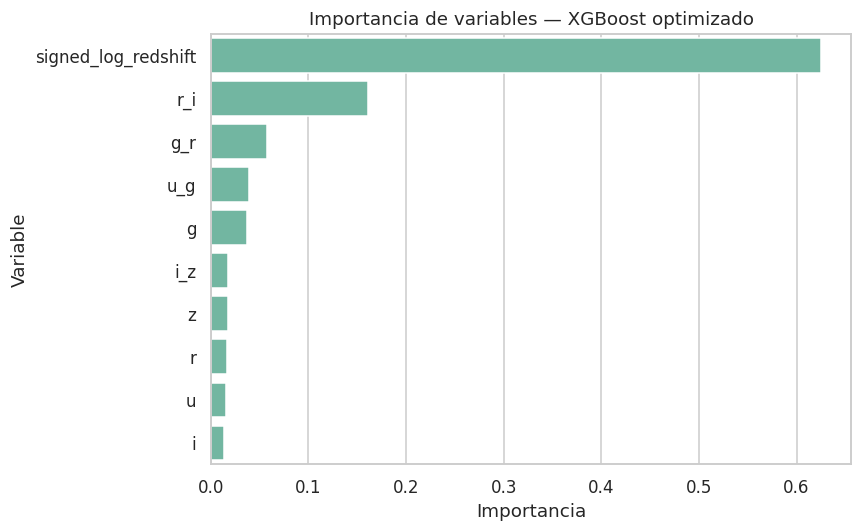

In [ ]:
# Importancia de variables del modelo final
modelo_estimador = (
    modelo_final.named_steps["model"]
    if isinstance(modelo_final, Pipeline)
    else modelo_final
)

if hasattr(modelo_estimador, "feature_importances_"):
    importancia = pd.DataFrame({
        "Variable": FEATURES_FINAL_CV,
        "Importancia": modelo_estimador.feature_importances_
    }).sort_values("Importancia", ascending=False)

    display(importancia.round(4))

    plt.figure(figsize=(8, 5))
    sns.barplot(data=importancia, x="Importancia", y="Variable")
    plt.title(f"Importancia de variables — {nombre_modelo_final}")
    plt.tight_layout()
    plt.show()
else:
    print("El modelo final no expone feature_importances_.")


**Interpretación de la importancia de variables**

| Grupo | Variables | Importancia total |
|---|---|---|
| Redshift | `signed_log_redshift` | **62,5%** |
| Índices de color | `r_i` (16,1%), `g_r` (5,8%), `u_g` (3,9%), `i_z` (1,8%) | **27,5%** |
| Magnitudes | `g`, `z`, `r`, `u`, `i` (1,4%–3,7% c/u) | **10,0%** |

> La importancia de XGBoost se mide por *gain*: cuánto mejora la función de pérdida, en promedio, cada vez que el modelo usa la variable para dividir. Indica cuánto se apoya el modelo en cada variable, no una relación causal.

**1. El redshift domina la clasificación** (62,5%), lo que confirma el hallazgo central del EDA: es la variable más discriminante y por sí sola separa casi por completo a las estrellas.

**2. Los índices de color son el segundo pilar** (27,5%) y casi triplican el aporte de las magnitudes. Esto confirma que la **forma del espectro** es más informativa que el brillo en bandas individuales.

**3. `r − i` es el color más importante (16,1%)**, por encima de `u − g` (3,9%), aunque el EDA destacaba `u − g` como el separador de quásares. Hay dos razones posibles:
- `r − i` separa a las galaxias del resto (mediana 0,72 vs. ≤ 0,21) y es especialmente útil en la **zona de solapamiento GALAXY–QSO**, donde se concentran las divisiones más difíciles y, por lo tanto, las de mayor *gain*.
- Buena parte de los quásares ya queda separada por el redshift, así que `u − g` aporta menos información *adicional*. Además, los colores están correlacionados entre sí (`g−r`–`r−i`: ρ = 0,78) y la importancia por *gain* tiende a concentrarse en una de las variables correlacionadas.

**4. `i − z` es el color menos importante (1,8%)**, igual que en el EDA, donde estrellas y quásares se solapaban casi por completo en ese índice.

**5. Importancia ≠ indispensabilidad.** Aunque los colores concentran el 27,5% de la importancia, en la comparación A/B/C eliminarlos (set C) solo redujo el F1 macro de XGBoost en 0,0010. Como los colores son diferencias de magnitudes, el modelo puede aproximarlos combinando divisiones sobre las bandas individuales. Los colores le **facilitan** el trabajo al modelo, pero la información de fondo también está en las magnitudes.

## Conclusiones finales

Se construyó un clasificador de **galaxias, estrellas y quásares** con 100.000 observaciones del SDSS DR17. El modelo final, **XGBoost optimizado**, alcanzó un **F1 macro de 0,9757 y una accuracy de 97,9% en test**, prácticamente igual a la validación cruzada (0,9758). El modelo **generaliza sin sobreajuste**.

**Datos y EDA**
- Se corrigieron tres problemas de calidad: una fila con valores -9999, la columna constante `rerun_ID` y `obj_ID`, que venía truncado en el archivo original.
- El **redshift** es la variable más discriminante y separa casi por completo a las estrellas. La principal dificultad es la frontera **GALAXY–QSO** (0,5 < z < 2), donde los **índices de color** ayudan a resolver la ambigüedad.
- La metadata técnica (`plate`, `MJD`, `fiber_ID`) predice la clase sin información física (F1 0,60), porque refleja los programas de observación del SDSS. **Se excluyó** para evitar ese atajo.

**Modelado**
- Los **ensambles de árboles** fueron los mejores (~0,975). La Regresión Logística quedó última (0,939), lo que confirma que **las fronteras entre clases no son lineales**.
- **Las magnitudes no se pueden eliminar:** sin el brillo total (solo colores), casi todos los modelos empeoran. Los colores no agregan información nueva, pero facilitan el trabajo de los árboles.
- La optimización aportó mejoras **marginales (+0,0012)**: el límite está en la información de las variables, no en el modelo. XGBoost empató con Random Forest y se eligió por ser **~14 veces más rápido**.

**Resultados por clase**
- **STAR** es casi perfecta (F1 0,995) y **GALAXY** muy sólida (F1 0,983).
- **QSO** es la clase más difícil (F1 0,950, recall 0,934). La mayoría de sus errores se clasifican como galaxias, tal como anticipó el EDA.
- **Importancia de variables:** redshift 62,5%, colores 27,5% y magnitudes 10%. El modelo aprendió lo mismo que usa la astronomía: **distancia y forma del espectro**.

**Limitaciones y trabajo futuro**
- El modelo se validó solo con datos del SDSS. El SVM usó una submuestra y XGBoost no tuvo ponderación de clases.
- La transformación `signed_log_redshift` perjudica a los modelos sensibles a la escala.
- **Próximos pasos:** mejorar el recall de QSO (ajuste de umbral o pesos de clase), probar `arcsinh(z/10⁻⁴)`, analizar los errores con SHAP y evaluar el modelo con datos de otro relevamiento.

## Referencias

1. fedesoriano (2022). *Stellar Classification Dataset - SDSS17*. Kaggle. https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17
2. Abdurro'uf et al. (2022). The Seventeenth Data Release of the Sloan Digital Sky Surveys. *ApJS, 259*(2), 35. https://doi.org/10.3847/1538-4365/ac4414
3. York, D. G. et al. (2000). The Sloan Digital Sky Survey: Technical summary. *AJ, 120*(3), 1579–1587. https://doi.org/10.1086/301513
4. Richards, G. T. et al. (2002). Spectroscopic target selection in the SDSS: The quasar sample. *AJ, 123*(6), 2945–2975. https://doi.org/10.1086/340187
5. Geirhos, R. et al. (2020). Shortcut learning in deep neural networks. *Nature Machine Intelligence, 2*, 665–673. https://doi.org/10.1038/s42256-020-00257-z
6. Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
7. Chen, T. & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proc. ACM SIGKDD*, 785–794.
8. Ke, G. et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *NeurIPS 30*, 3146–3154.
9. Bergstra, J. & Bengio, Y. (2012). Random search for hyper-parameter optimization. *JMLR, 13*, 281–305.
10. Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *JMLR, 12*, 2825–2830.